# Song Recognition from Humming and Whistling

Classical ML, small neural networks and pretrained audio models on 800 amateur recordings of 187 people

# 1 Author

**Artem Zeleniuk**

## Summary of results

Which of eight known songs is a person humming or whistling in a 10-second clip? On 800 amateur recordings of 187 people, tested only on people the model has never heard, the best single model of this study names the song correctly for 71.3% of the clips and 80.1% of the whole recordings, and the average of two models for 75.1% and 82.8%. Random guessing gives 12.5%, and gradient boosting on aggregated audio features, where the study starts, reaches 36.6%.

Most of that distance comes from one property of the task: a melody stays the same melody when it is moved to another key, and every person picks another key. A small 1D CNN on the chroma reaches 45.8% as it is, 66.0% when the 12 pitch classes are rotated at random during training, and a network with this invariance built in reaches 62.6%. Large pretrained audio networks stay behind this small network, frozen (43.3% at best) and fine-tuned (59.4%). Hyperparameter search, methods for noisy labels and a separate model for hums and for whistles add little or nothing on these data.

All numbers are for people who are not in the training data. The same models score 11.3 to 37.4 points higher when the overlapping clips of one recording are allowed on both sides of the split, and fall to the random baseline when the training labels are shuffled (section 6.10).

In [1]:
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
from humrec import config, evaluation, report

RESULTS = os.path.join(ROOT, "results")
pd.set_option("display.max_colwidth", 80, "display.width", 200)
clips, predictions = report.load_all(RESULTS)
models = report.model_table(clips, predictions)
plain = models[models["variant"] == ""]
comparisons = report.comparison_table(clips, predictions)


def show(rows):
    out = pd.DataFrame({
        "model": rows["model"], "input": rows["input"], "variant": rows["variant"].replace("", "plain"),
        "clip": (100 * rows["clip_accuracy"]).round(1), "± std": (100 * rows["clip_std"]).round(1),
        "interval": [f"{100 * a:.1f} to {100 * b:.1f}" for a, b in zip(rows["clip_ci_low"], rows["clip_ci_high"])],
        "recording": (100 * rows["recording_accuracy"]).round(1),
        "validation": (100 * rows["validation_accuracy"]).round(1), "train": (100 * rows["train_accuracy"]).round(1),
    })
    return out.reset_index(drop=True)


def named(names):
    return show(models.set_index("experiment").loc[names].reset_index())


def differences(rows):
    out = rows.copy()
    for column in ("difference", "ci_low", "ci_high"):
        out[column] = (100 * out[column]).round(1)
    return out.rename(columns={"difference": "A minus B, points"}).reset_index(drop=True)


print(len(clips), "clips,", clips["recording"].nunique(), "recordings,", clips["participant"].nunique(), "participants,",
      len(predictions), "saved experiments")

2852 clips, 800 recordings, 187 participants, 138 saved experiments


# 2 Problem Formulation

## 2.1 Task Description

The goal is to build a multi-class classification model that takes as an input an audio recording of **10 seconds** of duration and should identify which song a person is humming or whistling. Given a 10-second audio recording, the model must predict one of 8 possible songs:

1. **Feeling** - "I Gotta Feeling" by Black Eyed Peas
2. **Friend** - "You've Got a Friend in Me" from Toy Story
3. **Happy** - "Happy" by Pharrell Williams
4. **Married** - "Married Life" from Up
5. **Necessities** - "The Bare Necessities" from The Jungle Book
6. **NewYork** - "New York, New York" by Frank Sinatra
7. **RememberMe** - "Remember Me" from Coco
8. **TryEverything** - "Try Everything" by Shakira

## 2.2 Why is this problem challenging?

1. **Limited data**: Only 100 samples per class (800 total)
2. **High variability**: Different people hum/whistle the same song differently (tempo, pitch, accuracy)
3. **Data quality**: Some samples contain melodic imperfections: many participants hum or whistle off-key, change tempo mid-phrase, or struggle to reproduce the melody consistently.
4. **Two modalities**: Humming and whistling have very different timbres but represent the same melody
5. **No lyrics**: Must rely purely on melodic patterns

## 2.3 Why is this interesting?

1. Music-identification systems (similar to Shazam, but for humming/whistling).
2. Improving user experience in voice-based interfaces and smart assistants.
3. Foundations for query-by-humming retrieval systems.

The task is also a good exercise in working with **small, imperfect real-world datasets**, which are common in practical ML, and in audio processing and feature extraction.

# 3 Methodology

## 3.1 Research Approach

Every decision in this study is taken on experimental results rather than assumptions. The study follows the principle of **progressive complexity**: we begin with simple methods and add complexity only when the simpler ones have reached their limit. Before each step we state what we expect from it, and each family of methods is tuned until it stops improving before we move on. This way we understand *why* certain methods succeed or fail for this specific task.

## 3.2 Overall Strategy

We explore four categories of methods, progressing from simple to complex.

### Level 1: Classical ML with Aggregated Features

The first level gives a baseline and checks the data. If simple models fail completely, the problem is more likely in the preparation of the data or in the labels than in the models. Random Forest, XGBoost, LightGBM and SVM are compared on the same aggregated audio features, and the best of them is kept for the next level, so that from then on only the features change. Any more complex method has to beat this baseline.

### Level 2: Classical ML with Temporal Structure

Songs are temporal sequences: melody and rhythm unfold over time, and aggregation over the whole clip throws this order away. The second level keeps a coarse order with **segment-based features**: the clip is divided into N temporal segments, and the statistics are computed per segment. If the classical models stop improving even with this structure, their capacity is the limit for this amount of data, and we move on to neural networks.

### Level 3: Neural Networks

A 1D CNN can learn note transitions and short phrases directly from the sequence of frame-level features, without hand-made statistics, and around 2,800 segments are enough to train a network of moderate size.

**Hypothesis:** Neural networks will learn more discriminative temporal patterns than hand-crafted segment features.

If training from scratch is limited by the size of the dataset (overfitting, poor generalization), we move on to transfer learning.

### Level 4: Transfer Learning

Pre-trained models such as AST (Audio Spectrogram Transformer) have learned general audio representations from millions of recordings. Fine-tuning such a model needs less data than training from scratch, which addresses the main limitation of this task: around 800 original recordings.

**Hypothesis:** Transfer learning will achieve the highest accuracy by combining general audio understanding with task-specific fine-tuning.

### Beyond the four levels

The results of the four levels raised further questions, which are answered in the same way:

- **Invariance to the key** (section 6.5): the same melody in another key should give the same answer. We compare random key changes during training, a network that is invariant to the key by construction, and the pitch shift of the audio augmentation.
- **Methods for poor data** (section 6.7): a separate model for hums and for whistles, mixup with label smoothing, and the pruning of the least recognisable training recordings.
- **Checks of the protocol** (section 6.10): control experiments that show what a leak would look like on these data.

## 3.3 Train/Validation/Test Split

We use **group-aware stratified 5-fold cross-validation**. The participants are divided into five folds, stratified by song (157 to 164 recordings and 37 to 38 participants per fold). For each fold in turn:
- **Test set**: this fold (20%)
- **Validation set**: the next fold (20%), used for early stopping and for every choice of a setting
- **Training set**: the remaining three folds (60%)

Recordings of one person (subject_id) are always in the same split. This prevents data leakage where the model might learn to recognize a person's voice rather than the song.

Every recording is therefore tested exactly once, by a model that has seen neither it nor its participant. Every setting of a single training (the epoch at which it stops, the number of temporal segments, the encoder layer and so on) is chosen on the validation fold of that training. Three choices are made once for all folds, from the mean validation accuracy of the five splits: the final model, the members of two ensembles and the learning rate of the fine-tuning. Every fold is the validation fold of one split, so these three choices are not strictly separate from the test folds. Section 6.10 repeats the first two strictly per fold.

## 3.4 Evaluation Metrics

- **Primary**: Accuracy (proportion of correct predictions)
- **Secondary**: Confusion matrix (to identify which songs are systematically confused)
- **Baseline**: Random guessing = 12.5% (1/8 classes)
- **Improvement metric**: Percentage improvement over random baseline

Accuracy is reported at two levels:
- **clip accuracy**: the share of the 2,852 10-second clips whose song is predicted correctly,
- **recording accuracy**: the same for the 800 recordings, after the class probabilities of the clips of a recording have been averaged.

Every model with a random component is trained with 5 seeds, and we report the mean and the standard deviation over the seeds. Intervals are 95% intervals from 2,000 bootstrap resamples of the participants (clips of one person are not independent, so people are resampled, not clips).

## 3.5 Checks against Leakage

A result on data of this kind is easy to inflate by accident: clips of one recording overlap by half, and the recordings of one person share a voice, a microphone and a room. Four safeguards are part of the code.

- The folds are built from participants (`humrec/data.py`), and a test asserts that no participant is in two folds. Every model, the standardisation of its inputs, the selection of features, the choice of an encoder layer and every other setting see the training fold and the validation fold only.
- Augmented copies are made of training clips only, and every copy stays in the fold of its recording.
- All 800 audio files have different SHA-256 values, so no file is in the data twice under two names. `scripts/check_duplicates.py` also looks for copies with other bytes (another format, another loudness, a shift of the pitch as a whole) by comparing the pitch tracks of all pairs of clips.
- Three control experiments are run for a feature model, for the classifier on a frozen encoder and for the two strongest kinds of network: training with shuffled labels (the accuracy must fall to the random baseline), a split of the recordings at random (the participant is on both sides) and a split of the clips at random (overlapping clips of one recording are on both sides). The last two show how large the number would be under a careless split. On these data the split by recordings cannot reveal a shared participant (section 6.10 explains why), so the separation of the participants rests on the construction of the folds and its test.

# 4 Implemented ML Prediction Pipelines

## Overview

Our prediction pipeline transforms raw audio recordings into song predictions through three main stages:

```
Audio (10 sec, 22050 Hz) → Transformation → Model → Prediction (1 of 8 songs)
```

We implement multiple pipeline variants to systematically compare different approaches (Table 1).

**Table 1.** The pipeline variants.

| Pipeline | Transformation | Model | Input Shape |
|----------|---------------|-------|-------------|
| A | Aggregated features | XGBoost/LightGBM/SVM/Random Forest | (109,) |
| B | Segment features | XGBoost | (N_SEG × 54 × 2 + 1,) |
| C | Raw sequences | 1D CNN, LSTM | (431, 54), (431, 26) or (431, 14) |
| D | Raw sequences | 2D CNN, key-invariant 2D CNN | (431, 26, 1) or (431, 14, 1) |
| E | Pitch contour (pYIN) | 1D CNN, LSTM, XGBoost on contour statistics, melody matching | (431, 3) |
| F | Pretrained encoder | Small classifier on frozen embeddings, fine-tuning | (768,) or (1024,) |

## 4.1 Transformation Stage

**Input:** Raw audio waveform (10 seconds, sample rate 22050 Hz)

### Standard Feature Extraction (Pipelines A-D)

1. Load audio with `librosa`
2. Extract frame-level features with hop_length=512, which gives 431 frames per clip:
   - **MFCC** (13): Mel-frequency cepstral coefficients, captures timbre
   - **Chroma** (12): Pitch class representation, captures melody
   - **Delta MFCC** (13): Temporal derivatives, captures dynamics
   - **Tonnetz** (6): Tonal centroid features, captures harmonic relations
   - **Spectral** (7): Centroid, bandwidth, rolloff, contrast (4 values), captures texture
   - **Onset** (1): Onset strength, captures rhythm
   - **ZCR** (1): Zero crossing rate
   - **RMS** (1): Energy
3. Extract global tempo (1 value)

**Output formats:**
- **Aggregated:** mean and std of every feature across time, plus the tempo, which gives 109 features
- **Segment-based:** divide into N segments and compute mean and std per segment, which gives N × 54 × 2 + 1 features
- **Sequential:** keep the full time series, an array of shape (431, 54)

### Pitch Contour Extraction (Pipeline E)

The pitch of every frame is tracked with probabilistic YIN (`librosa.pyin`, 65 to 2,093 Hz) and expressed in semitones relative to the median pitch of the clip. The contour has three channels per frame: the relative pitch, a flag for voiced frames and the frame-to-frame change of the pitch.

**Why pitch contours:** A pitch tracker removes voice timbre and focuses on melody. A contour relative to its own median is key-invariant (same melody in different keys produces the same contour). This approach is inspired by Google's "Hum to Search" system.

### Feature Types

**Table 2.** The kinds of features and what they are for (Table 2 is a short guide, the full list is in section 5.5).

| Feature | Description | Why useful |
|---------|-------------|------------|
| **MFCC** | Mel-Frequency Cepstral Coefficients | Captures timbre (voice quality) |
| **Chroma** | Energy in each of 12 musical notes | Captures melody/harmony |
| **Spectral Centroid** | "Brightness" of sound | Distinguishes hum vs whistle |
| **Spectral Bandwidth** | Width of frequency content | Sound texture |
| **Zero Crossing Rate** | How often signal crosses zero | Percussive vs tonal |
| **RMS Energy** | Loudness over time | Dynamic patterns |
| **Tempo** | Speed of the performance | Rhythm information |

### Aggregation Strategies

1. **Statistical aggregation**: mean and std per feature
2. **Segment-based**: divide into N segments, compute stats per segment
3. **Raw sequence**: preserve full temporal structure (for neural networks)

## 4.2 Model Stage

We explore three categories of models with increasing complexity:

### Classical ML (on aggregated/segment features)
- **Random Forest**: Ensemble of decision trees, good baseline
- **XGBoost:** Gradient boosting, handles feature interactions, regularization against overfitting
- **LightGBM:** Faster training, leaf-wise growth, similar performance
- **SVM:** Effective in high-dimensional spaces with RBF kernel

### Neural Networks (on sequential features)
- **1D CNN:** Convolution along time axis - learns local temporal patterns (note transitions)
- **2D CNN:** Treats (time × features) as image - learns joint time-frequency patterns
- **Key-invariant 2D CNN:** 2D convolutions over time and the circle of the 12 pitch classes with circular padding, followed by the mean over the circle, so that a change of key cannot change the output
- **Bidirectional LSTM:** 32 units per direction, with its final states or with the mean of its outputs over time as the summary of the clip

### Transfer Learning (on waveforms and pitch contours)
- **Frozen pretrained encoders + small classifier:** AST, wav2vec 2.0, HuBERT, WavLM, Whisper and MERT turn a clip into one vector per layer, and a classifier with one hidden layer is trained on one layer
- **Fine-tuning:** the whole MERT 95M encoder is trained on the clips
- **Pitch tracking + CNN/LSTM:** the pitch tracker extracts the melody, the CNN captures local patterns, the LSTM captures sequential dependencies

The progression starts simple (classical ML) to establish baselines, adds complexity (CNN) to capture temporal structure, and then uses pretrained knowledge and pitch tracking to extract a melody that does not depend on the voice.

## 4.3 Ensemble Stage

We combine predictions from the best-performing models by averaging their class probabilities.

Models that see different aspects of the audio make different errors, and their average makes fewer.

Ways to combine predictions from multiple models:

1. **Voting**: Each model votes for a class, majority wins
2. **Averaging**: Average predicted probabilities, take argmax (used here)
3. **Stacking**: Train a meta-model on predictions of base models

# 5 Dataset

## 5.1 Data Source

We use the **MLEnd Hums and Whistles II Dataset** (800-sample version, see "Acknowledgements"). The repository contains no audio. `scripts/download_data.py` downloads the public archive and checks every file against [`data/manifest.csv`](../data/manifest.csv) (name, size and SHA-256). Table 3 describes the sample.

**Table 3.** The recordings.

| Property | Value |
|----------|-------|
| Total samples | 800 |
| Songs (classes) | 8 |
| Samples per song | 100 |
| Duration | 10.6 to 39.1 seconds, median 19.6 seconds, 4.8 hours in total |
| Format | WAV, 758 files at 44.1 kHz and 42 at 48 kHz, 372 mono and 428 stereo, loaded as 22050 Hz mono |
| Recording types | Humming (400) and Whistling (400) |
| Participants | 187, each with 1 to 5 recordings (median 4) |

**Filename format:** `S{subject_id}_{hum/whistle}_{take}_{song}.wav`

Example: `S105_whistle_2_Happy.wav` = Subject 105, whistling, take 2, song "Happy"

## 5.2 Setup and Data Loading

`scripts/download_data.py` fetches the audio, and `scripts/extract_features.py` writes one row per recording to `results/recordings.csv` and one row per 10-second clip to `results/clips.csv`.

In [2]:
recordings = pd.read_csv(os.path.join(RESULTS, "recordings.csv"))
summary = report.data_summary(RESULTS)
print("DATASET STATISTICS")
print("length of a recording in seconds: min %.1f, median %.1f, max %.1f, total %.1f hours" % (
    summary["duration_min"], summary["duration_median"], summary["duration_max"], summary["hours"]))
print("unique subjects:", recordings["participant"].nunique())
pd.crosstab(recordings["song"], recordings["kind"], margins=True)

DATASET STATISTICS
length of a recording in seconds: min 10.6, median 19.6, max 39.1, total 4.8 hours
unique subjects: 187


kind,hum,whistle,All
song,,,
Feeling,50,50,100
Friend,52,48,100
Happy,48,52,100
Married,51,49,100
Necessities,49,51,100
NewYork,51,49,100
RememberMe,50,50,100
TryEverything,49,51,100
All,400,400,800


### Dataset Summary

The dataset is well-balanced:
- 8 songs, 100 samples each (800 total)
- 2 modalities: humming (400) and whistling (400), split about 50/50 within every song
- 187 unique subjects means high diversity of voices

Implications for modeling:
- Balanced classes, so there is no need for class weighting
- Many subjects (187) with few samples each (about 4 per person), so the model must learn melody patterns, not individual voices
- Two modalities with different acoustic properties, so the model must generalize across humming and whistling

With about 4 recordings per subject and no subject recording a song twice, recognizing the voice does not help, so the model has to learn the melody.

## 5.3 Audio Exploration and Visualization

In this section, we visualize audio samples using key acoustic representations - waveform, mel spectrogram, MFCC, and chromagram, which will be used in our ML methods further, to examine variability between classes, modalities, and individual performances (Figure 1, Figure 2, Figure 3, drawn by `scripts/plot_examples.py`).

![Happy, hummed: waveform, mel spectrogram, MFCC and chromagram](../figures/example_Happy_hum.png)

**Figure 1.** "Happy", hummed.

![Happy, whistled: waveform, mel spectrogram, MFCC and chromagram](../figures/example_Happy_whistle.png)

**Figure 2.** "Happy", whistled.

**Interpretation**

Figure 1: Happy - Humming, Figure 2: Happy - Whistling

- Mel Spectrogram: Humming shows energy concentrated in lower frequencies (below about 2000 Hz) with visible harmonics, whistling produces a clear single pitch line around 1200-2000 Hz
- MFCC: Similar overall patterns but different coefficient distributions: humming has richer timbre
- Chromagram: Both show a similar shape of the melody, but on other pitch classes: the two performers are in different keys

Conclusion: Humming and whistling of the same song share melodic structure (chromagram) but differ significantly in timbre (MFCC) and spectral characteristics. The key differs from performer to performer, which becomes the central point of section 6.5.

![Friend, hummed: waveform, mel spectrogram, MFCC and chromagram](../figures/example_Friend_hum.png)

**Figure 3.** "Friend", hummed.

**Interpretation**

Figure 1: Happy - Humming, Figure 3: Friend - Humming

- Waveform: Both have similar amplitude range, but different temporal patterns (phrase structure, pauses)
- Mel Spectrogram: Different frequency distributions reflect distinct melodic contours
- Chromagram: Clearly different pitch class patterns: "Friend" and "Happy" have distinct melodic sequences

Conclusion: Different songs show distinct patterns across all representations, particularly in chromagram and mel spectrogram, which capture melodic information essential for classification.

## 5.4 Train/Validation/Test Split

The folds of section 3.3 are stored with every recording and every clip (Table 4). No participant is in two folds, so the data leakage check of the split (the number of participants shared by two folds) gives 0.

**Table 4.** The five folds.

| Fold | Recordings | Participants | Clips |
|---|---|---|---|
| 0 | 157 | 37 | 584 |
| 1 | 160 | 38 | 562 |
| 2 | 160 | 37 | 535 |
| 3 | 159 | 37 | 574 |
| 4 | 164 | 38 | 597 |

In [3]:
per_fold = recordings.groupby("fold").agg(recordings=("file", "size"), participants=("participant", "nunique"),
                                          hums=("kind", lambda k: int((k == "hum").sum())))
per_fold["clips"] = clips.groupby("fold").size()
shared = max(len(set(recordings.loc[recordings.fold == a, "participant"]) & set(recordings.loc[recordings.fold == b, "participant"]))
             for a in range(5) for b in range(a + 1, 5))
print("Data leakage check (should be 0): largest number of participants shared by two folds:", shared)
print("clips per recording: %.2f on average, %d clips are padded" % (summary["clips_per_recording_mean"], summary["padded_clips"]))
per_fold

Data leakage check (should be 0): largest number of participants shared by two folds: 0
clips per recording: 3.56 on average, 800 clips are padded


,recordings,participants,hums,clips
fold,,,,
0,157,37,70,584
1,160,38,89,562
2,160,37,85,535
3,159,37,82,574
4,164,38,74,597


## 5.5 Feature Engineering Strategy

### Approach: Extract First, Select Later

We extract **54 features per time frame**, then let algorithms determine importance:
- Classical ML uses feature selection (variance, correlation, importance-based)
- Neural networks learn relevant features through backpropagation

### Feature Categories

**Table 5.** The frame-level features (Table 5 lists all 54 and the tempo).

| Category | Features | Count | Purpose |
|----------|----------|-------|---------|
| **MFCC** | Mel-frequency cepstral coefficients | 13 | Timbre, vocal characteristics |
| **Delta MFCC** | Rate of change of MFCC | 13 | Timbre dynamics over time |
| **Chroma** | Energy per pitch class (C, C#, D...) | 12 | Melodic content - which notes |
| **Tonnetz** | Tonal centroid features | 6 | Harmonic relationships |
| **Spectral Centroid** | Center of mass of spectrum | 1 | Brightness of sound |
| **Spectral Bandwidth** | Width of spectrum | 1 | Narrow (whistle) vs broad (hum) |
| **Spectral Rolloff** | 85% energy frequency | 1 | Low vs high frequency content |
| **Spectral Contrast** | Peak-valley differences | 4 | Harmonic vs noise-like |
| **ZCR** | Zero crossing rate | 1 | Tonal vs noisy signal |
| **RMS Energy** | Root mean square | 1 | Loudness over time |
| **Onset Strength** | Note attack intensity | 1 | Rhythm and phrasing |
| **Tempo** | Beats per minute | 1 | Overall speed (global) |

**Total: 54 frame-level + 1 global = 55 features**

## 5.6 Data Augmentation Strategy

### The Challenge

With only 800 files for 8 classes (100 per class), our dataset is insufficient for robust neural network training. We address this through a two-stage dataset expansion approach.

### Stage 1: Segmentation with Overlap

We segment each audio file into overlapping 10-second clips to multiply our training data:

**Why segmentation?**
- Each file contributes multiple training examples
- Overlap ensures melodic phrases at segment boundaries are captured
- No artificial distortion (unlike pitch/time augmentation)

**Pre-processing steps:**

1. **Trim silence** from start and end, which removes dead air that adds no melodic information
2. **Skip short files** (shorter than 5 sec after trimming), because over-padded segments are mostly silence (no file of this sample is that short)
3. **Extract segments** with 50% overlap, so that each 5-second window appears in 2 segments

**Table 6.** The parameters of the segmentation (Table 6).

| Parameter | Value | Rationale |
|-----------|-------|-----------|
| Segment duration | 10 sec | Task definition |
| Overlap | 50% (5 sec step) | Each moment captured in about 2 segments |
| Minimum length | 5 sec | Avoid heavily padded segments |

As a result, 800 files turned into 2,852 segments (3.6× increase), of which 800 are padded with zeros (the last segment of every recording).

### Stage 2: Audio Augmentation

#### Standard or conservative parameters?

Our first experiments suggested that industry-standard augmentation parameters produce **worse results** than training on original data, and that the transformations alter the melodic characteristics that distinguish songs from each other. The measurement with five folds and five seeds does not confirm this for the network (section 6.4), so three sets of parameters are compared (Table 7). In the first two every transform is applied to a training segment with probability 0.4, and each application adds one more training segment. In the third every segment gets four extra copies, each changed by all three transforms at once.

**Table 7.** The augmentation arms.

| Arm | Pitch shift | Time stretch | Noise |
|-----|-------------|--------------|-------|
| Conservative | ±0.5 semitones | none | 0.0001 amplitude |
| Standard (strong) | ±2 semitones | ±10% | 0.005 amplitude |
| Combined | ±3 semitones | ±15% | 0.005 amplitude, all three on each of four copies |

Validation and test segments are never augmented.

#### Diagnostic Approach

We developed two diagnostic metrics to find "safe" augmentation parameters:

**Metric 1: Feature Correlation**
- Compare MFCC/Chroma features before and after augmentation
- If the chroma correlation falls below 0.5, the melody is destroyed
- If the MFCC correlation falls below 0.9, the timbre is significantly altered

**Metric 2: Class Separability**
- Compute ratio: (inter-class distance) / (intra-class distance)
- Higher ratio = classes are more distinguishable
- If the ratio drops after augmentation, the augmentation hurts classification

The numbers of both metrics are in section 6.4.

#### Conservative Strategy

Based on diagnostics, the conservative arm uses minimal augmentation:

```
Augmentation applied to 40% of training segments, per transform:
- Noise: amplitude 0.0001 (barely perceptible)
- Pitch: ±0.5 semitones (quarter tone)
```

**Result:** Training set increased by **81%** (40% per transform) while preserving class separability.

**Why only 40%?** Conservative approach: we prioritize maintaining class structure over maximizing data volume. An augmented sample that confuses the model is worse than no augmentation. Section 6.4 measures whether this caution is needed.

# 6 Experiments and Results

Every number in this section is computed by `scripts/make_report.py` from the saved predictions and is stored in `results/tables/` and `results/metrics.json`. Accuracies are in percent. "Clips" is the accuracy on the 2,852 clips, "Recordings" the accuracy on the 800 recordings after the clip probabilities of a recording are averaged. The number after ± is the standard deviation over 5 training seeds, and the intervals are 95% bootstrap intervals over participants. Validation and training accuracy are means over folds and seeds. Differences between two experiments are computed from the unrounded accuracies, so they can differ by 0.1 from the difference of two rounded numbers. The full list of all experiments is in [`results/tables/models.csv`](../results/tables/models.csv).

## 6.1 Feature Extraction

The features of section 5.5 are computed once for every segment and stored (`scripts/extract_features.py`), for the original segments and for the augmented copies of every arm. The pitch tracks (`scripts/extract_pitch.py`) and the embeddings of the pretrained encoders (`scripts/extract_embeddings.py`) are stored in the same way, so that every model reads the same inputs.

## 6.2 Classical ML methods with Aggregated Features

### Why Start Here?

Before exploring complex methods and neural networks, we need to answer fundamental questions:

1. **Is the data valid?** - If simple models fail completely, the problem might be in data preparation, not model complexity
2. **What's the baseline?** - Any advanced method must beat this, otherwise complexity adds no value

Starting with simple aggregation is also useful in order to determine which algorithm family works best for more complex methods.

This "simple first" approach prevents wasted effort on sophisticated architectures when the bottleneck is elsewhere.

**The Approach:** We aggregate temporal features into fixed-size vectors:

```
Audio (431 frames × 54 features) → mean + std → 109 features
```

This discards temporal order but captures the overall "statistical fingerprint" of each melody.

### Hypothesis

**H1:** Gradient boosting (XGBoost) will outperform SVM and Random Forest due to its ability to iteratively correct errors and learn feature interactions, which is critical when melodic differences are subtle.

**H2:** Aggregated features alone can exceed 30% accuracy (vs 12.5% random baseline) because tempo, chroma distribution, and spectral statistics carry significant discriminative information even without temporal structure.

### Algorithms Compared

**Table 8.** The algorithms on aggregated features (Table 8).

| Algorithm | Key Property |
|-----------|-------------|
| XGBoost | Sequential error correction, regularization |
| LightGBM | Leaf-wise growth, faster on large features |
| Random Forest | Parallel trees, feature importance |
| SVM (RBF) | Effective in high-dimensional spaces |

### Feature Importance Analysis

To validate our hypothesis that **tempo and melodic features** are most discriminative for song recognition, we analyze feature importance using **Random Forest**.

**Why Random Forest for feature importance?**
- Provides built-in importance scores based on how much each feature reduces impurity
- Robust to feature scale - no normalization needed
- Captures non-linear relationships between features and classes

**Hypothesis:** Tempo, rhythm features (onset strength), and melodic features (chroma, tonnetz) should rank highest, confirming that songs are distinguished by their rhythmic and melodic patterns rather than just timbre.

![The most important aggregate statistics of the random forest](../figures/feature_importance.png)

**Figure 4.** Importance of the aggregate statistics in the random forest, mean of 25 forests (5 folds, 5 seeds). The dashed line is the level of an input that is used like every other.

**Table 9.** Importance in the random forest by feature group. The last column is the mean importance of one input of the group divided by the uniform level 1/109.

| Feature group | Inputs | Sum of importance | Mean importance of an input, relative to the uniform level |
|---|---|---|---|
| tempo | 1 | 0.030 | 3.24 |
| onset strength | 2 | 0.030 | 1.64 |
| tonnetz | 12 | 0.123 | 1.12 |
| RMS energy | 2 | 0.020 | 1.07 |
| chroma | 24 | 0.229 | 1.04 |
| MFCC | 26 | 0.237 | 1.00 |
| spectral contrast | 8 | 0.068 | 0.92 |
| spectral bandwidth | 2 | 0.016 | 0.89 |
| spectral roll-off | 2 | 0.016 | 0.88 |
| zero-crossing rate | 2 | 0.016 | 0.87 |
| spectral centroid | 2 | 0.015 | 0.84 |
| delta MFCC | 26 | 0.199 | 0.84 |

uniform level: 0.0092
       feature          group statistic  importance  importance_std  forests
         tempo          tempo     value      0.0297          0.0020       25
onset_strength onset_strength      mean      0.0155          0.0012       25
onset_strength onset_strength       std      0.0146          0.0013       25
     tonnetz_2        tonnetz       std      0.0134          0.0018       25
     tonnetz_4        tonnetz      mean      0.0130          0.0009       25
      chroma_6         chroma      mean      0.0119          0.0013       25
      chroma_9         chroma      mean      0.0113          0.0012       25
     tonnetz_1        tonnetz      mean      0.0113          0.0013       25
     tonnetz_3        tonnetz      mean      0.0112          0.0008       25
        mfcc_9           mfcc      mean      0.0112          0.0008       25
  delta_mfcc_1     delta_mfcc       std      0.0111          0.0012       25
      chroma_7         chroma       std      0.0111   

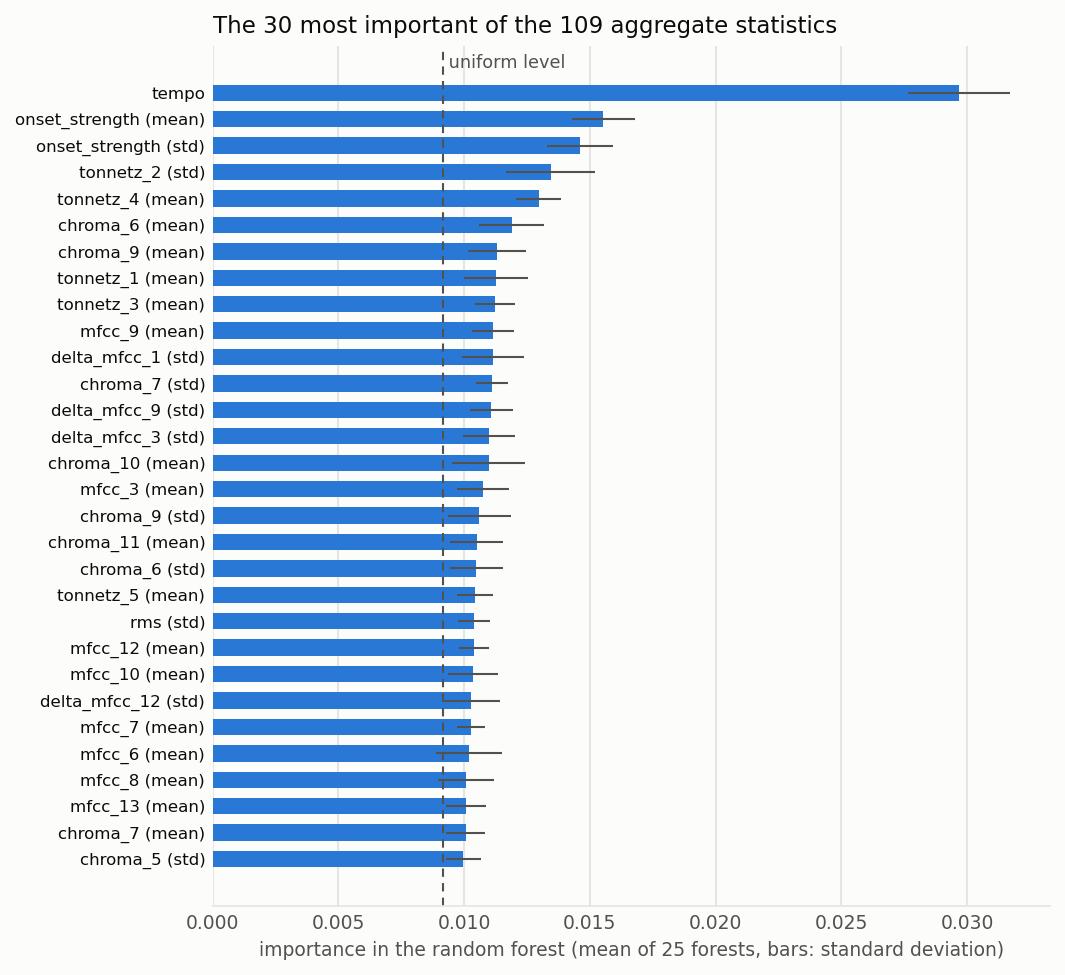

In [4]:
importance = pd.read_csv(os.path.join(RESULTS, "feature_importance.csv"))
print("uniform level: %.4f" % (1 / len(importance)))
print(importance.head(20).to_string(index=False, float_format=lambda v: "%.4f" % v))
_ = report.figure_importance(importance)

**Interpretation:**

The plot (Figure 4) agrees with the first part of our hypothesis: tempo and rhythm rank highest. The five most important inputs are `tempo` (3.2 times the uniform level), `onset_strength (mean)` (1.7 times the uniform level), `onset_strength (std)` (1.6 times the uniform level), `tonnetz_2 (std)` (1.5 times the uniform level), `tonnetz_4 (mean)` (1.4 times the uniform level). By group (Table 9), the tempo is used 3.2 times and the onset strength 1.6 times as much as an average input. The melodic features follow at a small distance: the tonnetz and chroma inputs are used 1.12 and 1.04 times as much as an average input, the MFCC 1.00 times. So the forest relies on rhythm clearly more than on anything else, and on melody only slightly more than on timbre. The importances are spread thinly: the forest uses all 109 inputs, and no single one carries the decision. The ranking supports the hypothesis without proving it, because impurity importance says how often a feature is used, not how much accuracy depends on it.

### Algorithms comparison

**Table 10.** Four algorithms on the 109 aggregated features.

| Model | Input | Variant | Clips, % | 95% interval | Recordings, % | 95% interval | Validation, % | Train, % |
|---|---|---|---|---|---|---|---|---|
| Random forest | mean and std over time (109 numbers) | plain | 32.1 ± 0.4 | 29.7 to 34.6 | 35.3 ± 0.9 | 32.2 to 38.5 | 32.6 | 100.0 |
| SVM (RBF kernel) | mean and std over time (109 numbers) | plain | 29.7 ± 0.1 | 26.9 to 32.5 | 33.1 ± 0.2 | 29.4 to 36.8 | 29.5 | 100.0 |
| LightGBM | mean and std over time (109 numbers) | plain | 35.8 ± 0.3 | 33.2 to 38.4 | 40.0 ± 0.6 | 36.6 to 43.3 | 35.6 | 88.0 |
| XGBoost | mean and std over time (109 numbers) | plain | 36.6 ± 0.3 | 34.0 to 39.4 | 41.1 ± 0.5 | 37.8 to 44.5 | 37.3 | 91.9 |

In [5]:
named([f"{m}__aggregate__none" for m in ("random_forest", "svm", "lightgbm", "xgboost")])

,model,input,variant,clip,± std,interval,recording,validation,train
0,Random forest,mean and std over time (109 numbers),plain,32.1,0.4,29.7 to 34.6,35.3,32.6,100.0
1,SVM (RBF kernel),mean and std over time (109 numbers),plain,29.7,0.1,26.9 to 32.5,33.1,29.5,100.0
2,LightGBM,mean and std over time (109 numbers),plain,35.8,0.3,33.2 to 38.4,40.0,35.6,88.0
3,XGBoost,mean and std over time (109 numbers),plain,36.6,0.3,34.0 to 39.4,41.1,37.3,91.9


### 6.2.1 Conclusions from Baseline Experiments

**Key Findings:**

1. **Gradient boosting methods outperform simpler models.** XGBoost and LightGBM achieve the highest accuracy on both validation and test folds (Table 10), confirming H1: boosting handles this task better than the SVM and the Random Forest.

2. **All models significantly exceed random baseline.** Even simpler models like SVM achieved results close to or above 30% (29.7% for the SVM, 32.1% for the Random Forest), well above the 12.5% random chance, confirming H2: our aggregated features carry meaningful discriminative information.

3. **Overfitting persists despite regularization.** Even with early stopping and L1/L2 penalties, all models show a gap between training and validation accuracy. This will be addressed in improved approaches.

**Decision:** XGBoost shows the best overall performance and will be used as our primary model for further experiments with temporal feature representations.

### Aggregated features with augmented data

The same four models were trained again with the conservative and with the standard (strong) augmentation of section 5.6 (Table 11, which also holds the 1D CNN of section 6.4 for comparison).

**Table 11.** Clip accuracy without augmentation and with the conservative and the strong arm.

| Model | No augmentation, % | Conservative, % | Difference, points (95% interval) | Strong, % | Difference, points (95% interval) |
|---|---|---|---|---|---|
| Random forest | 32.1 ± 0.4 | 31.9 ± 0.3 | -0.2 (-0.9 to +0.5) | 31.4 ± 0.4 | -0.7 (-1.6 to +0.2) |
| SVM | 29.7 ± 0.1 | 28.9 ± 0.1 | -0.8 (-1.9 to +0.2) | 27.5 ± 0.1 | -2.2 (-3.6 to -0.8) |
| XGBoost | 36.6 ± 0.3 | 36.4 ± 0.4 | -0.2 (-1.2 to +0.8) | 35.6 ± 0.3 | -1.0 (-2.3 to +0.2) |
| LightGBM | 35.8 ± 0.3 | 35.9 ± 0.4 | +0.1 (-1.0 to +1.3) | 34.8 ± 0.2 | -1.0 (-2.4 to +0.4) |
| 1D CNN | 45.8 ± 1.0 | 55.6 ± 0.7 | +9.8 (+8.5 to +11.1) | 62.7 ± 0.7 | +16.9 (+15.1 to +18.6) |

For the four models on aggregated features no arm changes the accuracy by more than 2.2 points, and the strong arm lowers it slightly. Augmentation gives these models little that is new: section 6.4 shows that the transforms leave the MFCC statistics almost unchanged.

## 6.3 Preserving Temporal Structure

### Why This Step?

Aggregated features (mean/std over entire clip) lose **melodic sequence**: the order of notes that defines a melody. "Do-Re-Mi" and "Mi-Re-Do" have identical statistics but are completely different melodies.

### Approach: Segment-Based Features

We divide each 10-second audio into **N segments** and compute statistics for each segment separately:

```
Audio (10 sec) → [Seg1] [Seg2] [Seg3] [Seg4] → Stats per segment → Concatenate
```

This preserves **coarse temporal structure**: the model knows WHERE in the clip certain patterns occur.

**Feature vector size:** N_SEGMENTS × 54 features × 2 (mean+std) + 1 (tempo)

### Feature Selection

As mentioned above our approach implies taking more features from the beginning and selecting the most important ones algorithmically. Now, with N_SEGMENTS = 4, we get **433 features**. This creates problems:

1. **Curse of dimensionality** - with about 1,700 training clips, 433 features leads to overfitting
2. **Redundant features** - many features are highly correlated (e.g., MFCC coefficients)
3. **Noise** - low-variance features add noise without information

### Our Feature Selection Pipeline

We apply a **3-stage filter** (in order, Table 12):

**Table 12.** The stages of the feature selection.

| Stage | Method | Purpose |
|-------|--------|--------|
| 1 | Variance Threshold | Remove near-constant features |
| 2 | Correlation Filter (correlation above 0.85) | Remove redundant features |
| 3 | SelectFromModel (RF importance) | Keep only informative features |

**Important:** Feature selection is fit on training data only to prevent data leakage.

### Optimization Strategy

We optimize parameters in **two stages**, from most impactful to fine-tuning:

**Stage 1: Structural Parameter (N_SEGMENTS)**

The number of segments fundamentally changes the feature representation:
- Fewer segments (4) capture broad temporal patterns
- More segments (20) capture fine-grained changes

We test N_SEGMENTS of 4, 5, 6, 8, 10, 12, 16 and 20 with a quick XGBoost and select the best on the validation fold, separately for every test fold.

**Stage 2: Model Hyperparameters**

Once optimal N_SEGMENTS is found, we tune XGBoost hyperparameters using **RandomizedSearchCV**:
- `max_depth`, `learning_rate`, `n_estimators`
- `reg_alpha`, `reg_lambda` (regularization)
- `subsample`, `colsample_bytree`

**Why RandomizedSearchCV?** Grid search is too slow with many parameters. Randomized search samples 30 combinations with 3-fold CV (inside the training folds, with participants kept together), which is efficient and effective.

**Table 13.** Validation accuracy of the quick XGBoost by the number of segments, mean of the five folds.

| Parts | 4 | 5 | 6 | 8 | 10 | 12 | 16 | 20 |
|---|---|---|---|---|---|---|---|---|
| Validation accuracy, % | 40.1 | 40.0 | 40.6 | 41.7 | 40.5 | 42.2 | 41.7 | 41.9 |

number of segments chosen per fold: {'0': 12, '1': 8, '2': 4, '3': 16, '4': 6}


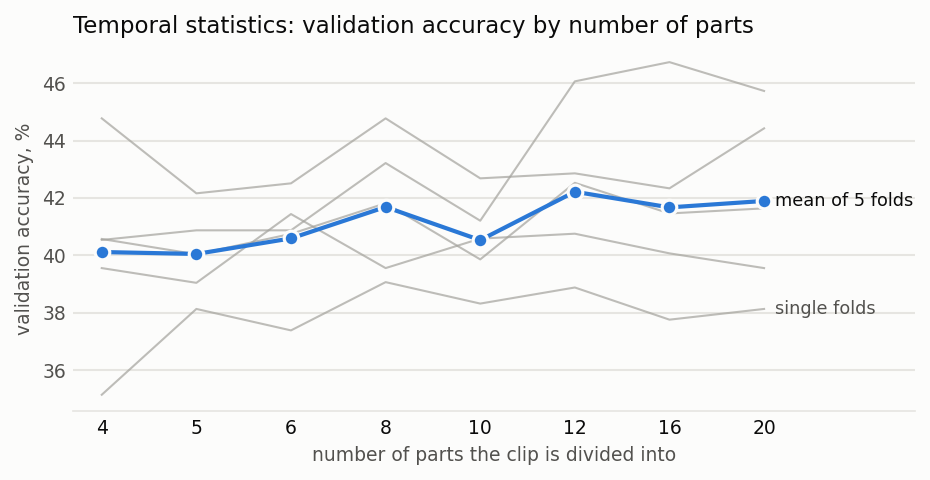

In [6]:
with open(os.path.join(RESULTS, "temporal_sweep.json")) as handle:
    sweep = json.load(handle)
print("number of segments chosen per fold:", sweep["chosen"])
_ = report.figure_parts(sweep)

The validation accuracy is flat between 4 and 20 segments (Table 13), and the best number differs from fold to fold (12, 8, 4, 16, 6 for the five folds).

**Table 14.** XGBoost on aggregated features, on segment features and on segment features with tuned hyperparameters.

| Model | Input | Variant | Clips, % | 95% interval | Recordings, % | 95% interval | Validation, % | Train, % |
|---|---|---|---|---|---|---|---|---|
| XGBoost | mean and std over time (109 numbers) | plain | 36.6 ± 0.3 | 34.0 to 39.4 | 41.1 ± 0.5 | 37.8 to 44.5 | 37.3 | 91.9 |
| XGBoost | mean and std in N parts of the clip, selected | plain | 40.9 ± 0.1 | 38.0 to 43.7 | 47.9 ± 0.6 | 44.1 to 51.6 | 41.7 | 98.8 |
| XGBoost | mean and std in N parts of the clip, selected, tuned XGBoost settings | plain | 41.0 ± 0.3 | 38.1 to 43.9 | 48.4 ± 0.4 | 44.6 to 52.2 | 42.3 | 100.0 |

In [7]:
named(["xgboost__aggregate__none", "xgboost__temporal__none", "xgboost__temporal_tuned__none"])

,model,input,variant,clip,± std,interval,recording,validation,train
0,XGBoost,mean and std over time (109 numbers),plain,36.6,0.3,34.0 to 39.4,41.1,37.3,91.9
1,XGBoost,"mean and std in N parts of the clip, selected",plain,40.9,0.1,38.0 to 43.7,47.9,41.7,98.8
2,XGBoost,"mean and std in N parts of the clip, selected, tuned XGBoost settings",plain,41.0,0.3,38.1 to 43.9,48.4,42.3,100.0


### Conclusions: Segment-Based XGBoost

**Results** (Table 14):
- Training Accuracy: 98.8%
- Validation Accuracy: 41.7%
- Test Accuracy: 40.9%

**Key Observations:**

1. **Overfitting persists** despite early stopping and regularization (L1/L2, max_depth=3, min_child_weight=5). The gap between train (99%) and validation (42%) remains significant.

2. **Segment features improve over aggregated**: test accuracy increased from 36.6% (aggregated) to 40.9% (segment-based), a difference of 4.2 points (+2.3 to +6.2), confirming that preserving temporal structure helps.

3. **Feature selection reduced dimensions by 68%**: from 995 to 315 features on average over the folds, without hurting performance (validation accuracy 41.7% after the selection, against 42.2% at best for the quick XGBoost on all columns in Table 13). This confirms many segment features were redundant.

4. **Hyperparameter tuning adds nothing**: the randomized search changes the test accuracy by +0.1 points (-0.7 to +0.9), so the limit of this family is the input, not the settings.

**Conclusion:** Segment-based features provide modest improvement, but classical ML on hand-crafted features has limited capacity. Next, we explore neural networks that can learn temporal patterns directly from raw sequences.

## 6.4 Neural Networks

### Why Neural Networks?

Classical ML methods (XGBoost, SVM) showed persistent overfitting despite regularization. The fundamental limitation: **hand-crafted aggregations (mean/std) lose the sequential structure of melodies**.

A CNN can learn local patterns such as note transitions and short melodic motifs directly from the sequence of frame-level features. Instead of designing the temporal representation by hand (segment-based features), we let the network learn it.

### Feature Selection for CNN

Based on conclusions from classical ML experiments: for melody recognition, **pitch and rhythm features are most important**. We experimented with training CNNs on different feature sets (Table 15):

**Table 15.** The feature sets for the networks.

| Mode | Features | Count | Rationale |
|------|----------|-------|-----------|
| `all` | MFCC, Chroma, Delta, Tonnetz, Spectral, Onset, ZCR | 54 | Full feature set |
| `melody` | Chroma + Onset + Tempo | 14 | Core melodic features |
| `melody_full` | Chroma + Delta_Chroma + Onset + Tempo | 26 | Melodic features with their frame-to-frame change |

**Table 16.** Sequence models on the frame-level features, without augmentation.

| Model | Input | Variant | Clips, % | 95% interval | Recordings, % | 95% interval | Validation, % | Train, % |
|---|---|---|---|---|---|---|---|---|
| 1D CNN | all 54 frame-level features | plain | 31.9 ± 0.8 | 29.8 to 34.4 | 34.1 ± 1.2 | 31.7 to 36.9 | 35.0 | 76.2 |
| 1D CNN | chroma, chroma difference, onset, tempo (26 channels) | plain | 45.8 ± 1.0 | 43.0 to 48.7 | 50.8 ± 1.3 | 47.4 to 54.2 | 47.6 | 80.5 |
| 1D CNN | chroma, onset, tempo (14 channels) | plain | 53.3 ± 1.7 | 50.4 to 56.4 | 60.0 ± 2.5 | 56.6 to 63.5 | 53.5 | 87.9 |
| 2D CNN | chroma, chroma difference, onset, tempo (26 channels) | plain | 56.5 ± 0.7 | 53.4 to 59.3 | 64.3 ± 1.7 | 61.0 to 67.6 | 58.0 | 98.8 |
| Bidirectional LSTM | all 54 frame-level features | plain | 17.4 ± 0.2 | 16.1 to 18.6 | 19.2 ± 0.6 | 17.2 to 21.1 | 19.3 | 54.6 |
| Bidirectional LSTM, mean over time | all 54 frame-level features | plain | 27.0 ± 0.5 | 25.0 to 29.3 | 28.7 ± 0.8 | 26.0 to 31.4 | 29.4 | 73.3 |
| Bidirectional LSTM, mean over time | chroma, onset, tempo (14 channels) | plain | 35.5 ± 0.6 | 33.5 to 37.5 | 41.5 ± 1.3 | 38.7 to 44.4 | 37.5 | 48.1 |

In [8]:
named(["cnn1d__frames__none", "cnn1d__melody_full__none", "cnn1d__melody__none", "cnn2d__melody_full__none",
       "bilstm__frames__none", "bilstm_pool__frames__none", "bilstm_pool__melody__none"])

,model,input,variant,clip,± std,interval,recording,validation,train
0,1D CNN,all 54 frame-level features,plain,31.9,0.8,29.8 to 34.4,34.1,35.0,76.2
1,1D CNN,"chroma, chroma difference, onset, tempo (26 channels)",plain,45.8,1.0,43.0 to 48.7,50.8,47.6,80.5
2,1D CNN,"chroma, onset, tempo (14 channels)",plain,53.3,1.7,50.4 to 56.4,60.0,53.5,87.9
3,2D CNN,"chroma, chroma difference, onset, tempo (26 channels)",plain,56.5,0.7,53.4 to 59.3,64.3,58.0,98.8
4,Bidirectional LSTM,all 54 frame-level features,plain,17.4,0.2,16.1 to 18.6,19.2,19.3,54.6
5,"Bidirectional LSTM, mean over time",all 54 frame-level features,plain,27.0,0.5,25.0 to 29.3,28.6,29.4,73.3
6,"Bidirectional LSTM, mean over time","chroma, onset, tempo (14 channels)",plain,35.5,0.6,33.5 to 37.5,41.5,37.5,48.1


**The best results of the 1D CNN came from `melody` (Chroma + Onset + Tempo):** 53.3%, against 45.8% for `melody_full` and 31.9% for all 54 features (Table 16). Fewer channels are better here, and this confirms the hypothesis of Level 3: the 1D CNN on 14 channels is 12.5 points above the best XGBoost on segment features.

Delta_Chroma (the frame-to-frame change of the chroma) was meant to provide key-invariance. It does not: the same melody transposed to another key still moves the energy to other pitch classes, and so does its change. Section 6.5 shows what does provide it. The 2D CNN, whose filters are 3 channels wide and therefore respond to a pattern of neighbouring pitch classes wherever it lies, is ahead of the 1D CNN on the same input, which fits that picture.

The LSTM with its final states as the summary of the clip learns little that carries over to new participants: 54.6% on its training clips and 17.4% on the test clips. With the mean of its outputs over time and a larger learning rate it reaches 27.0% on the 54 features and 35.5% on the chroma, below the 1D CNN on the same inputs. The recurrent models were not tuned further, so these rows say that an LSTM of this size is not a shortcut here, not that recurrent models cannot do the task.

### Augmentation helps the network and not the trees

For the 1D CNN the two arms of Table 11 add 9.8 and 16.9 points (Figure 5). The expectation of section 5.6, that standard parameters hurt, does not hold for the network. Table 17 separates the transforms and adds a control in which the training clips are only repeated, so that an epoch has as many clips as in the conservative arm.

![Clip accuracy of five models without augmentation and with two augmentation arms](../figures/augmentation.png)

**Figure 5.** The numbers of Table 11 as bars, with the spread over the seeds.

,a,b,"A minus B, points",ci_low,ci_high,interval_excludes_zero
0,random_forest__aggregate__conservative,random_forest__aggregate__none,-0.2,-0.9,0.5,False
1,random_forest__aggregate__strong,random_forest__aggregate__none,-0.7,-1.6,0.2,False
2,svm__aggregate__conservative,svm__aggregate__none,-0.8,-1.9,0.2,False
3,svm__aggregate__strong,svm__aggregate__none,-2.2,-3.6,-0.8,True
4,xgboost__aggregate__conservative,xgboost__aggregate__none,-0.2,-1.2,0.8,False
5,xgboost__aggregate__strong,xgboost__aggregate__none,-1.0,-2.3,0.2,False
6,lightgbm__aggregate__conservative,lightgbm__aggregate__none,0.1,-1.0,1.3,False
7,lightgbm__aggregate__strong,lightgbm__aggregate__none,-1.0,-2.4,0.4,False
8,cnn1d__melody_full__conservative,cnn1d__melody_full__none,9.8,8.5,11.1,True
9,cnn1d__melody_full__strong,cnn1d__melody_full__none,16.9,15.1,18.6,True


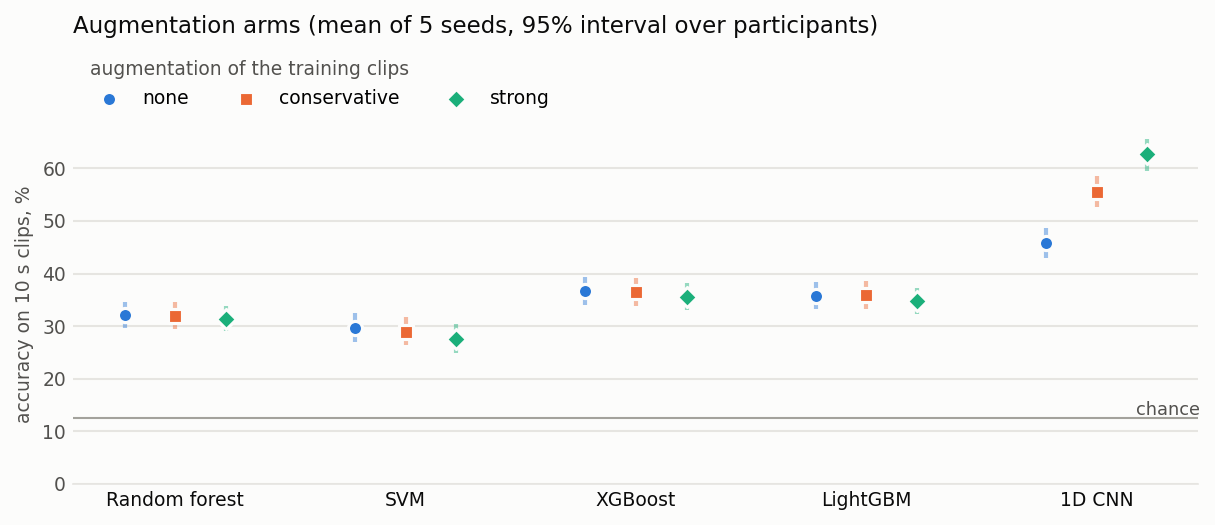

In [9]:
_ = report.figure_augmentation(models)
differences(comparisons[comparisons["a"].str.endswith(("__conservative", "__strong"))
                        & comparisons["a"].str.contains("__aggregate__|cnn1d__melody_full__")])

**Table 17.** The 1D CNN on the chroma with differences: the arms taken apart.

| Training set of the 1D CNN | Training clips per fold | Clips, % | Difference to no augmentation, points (95% interval) |
|---|---|---|---|
| No augmentation | 1,711 | 45.8 ± 1.0 | reference row |
| No augmentation, clips repeated as often as in the conservative arm | 3,101 | 49.3 ± 1.8 | +3.5 (+2.5 to +4.5) |
| Noise 0.0001 only | 2,414 | 49.4 ± 1.2 | +3.5 (+2.5 to +4.6) |
| Pitch shift up to 0.5 semitones only | 2,399 | 54.4 ± 0.6 | +8.6 (+7.4 to +9.9) |
| Conservative arm (both) | 3,101 | 55.6 ± 0.7 | +9.8 (+8.5 to +11.1) |
| Noise 0.005 only | 2,384 | 53.9 ± 1.0 | +8.1 (+6.8 to +9.3) |
| Pitch shift up to 2 semitones only | 2,389 | 56.6 ± 0.5 | +10.8 (+9.5 to +12.2) |
| Time stretch up to 10% only | 2,393 | 53.5 ± 1.6 | +7.7 (+6.5 to +8.9) |
| Strong arm (all three) | 3,744 | 62.7 ± 0.7 | +16.9 (+15.1 to +18.6) |
| Combined arm (4 copies, all three at once) | 8,556 | 70.0 ± 0.4 | +24.2 (+21.9 to +26.3) |

Repeating unchanged clips already adds 3.5 points, and noise of 0.0001 adds nothing beyond that. This part of the gain of the conservative arm is therefore an effect of the training schedule (more steps per epoch with the same early stopping), not of the changed audio. The pitch shift carries most of the rest, and the larger pitch shift, the time stretch and the audible noise of the strong arm each help on their own and more together.

The two diagnostic metrics of section 5.6 show what the transforms do to the features of a recording (Table 18, `scripts/augmentation_diagnostic.py`). The frame-level MFCC stay almost the same under every transform, while the chroma changes quickly with the pitch shift, as it must: a shift by k semitones moves the energy by k pitch classes. A low chroma correlation therefore does not mean that the melody is destroyed. It means that the melody is now in another key, which is exactly what the network needs to see.

**Table 18.** Correlation of the features of a clip before and after a transform (1.000 means no change), and the ratio of between-song to within-song distances of the aggregate statistics (a larger ratio means that the songs lie further apart).

| Transform | MFCC correlation | Chroma correlation | Separability ratio |
|---|---|---|---|
| original | 1.000 | 1.000 | 1.032 |
| noise 0.0001 | 1.000 | 0.985 | 1.024 |
| noise 0.0005 | 0.998 | 0.921 | 0.998 |
| noise 0.001 | 0.996 | 0.892 | 0.986 |
| noise 0.002 | 0.992 | 0.872 | 0.984 |
| noise 0.005 | 0.986 | 0.788 | 0.991 |
| pitch +0.5 semitones | 0.998 | 0.731 | 1.028 |
| pitch +1 semitones | 0.998 | 0.599 | 1.021 |
| pitch +2 semitones | 0.995 | 0.204 | 1.021 |
| stretch x1.02 | 0.976 | 0.444 | 1.031 |
| stretch x1.05 | 0.967 | 0.248 | 1.050 |
| stretch x1.1 | 0.960 | 0.151 | 1.039 |

In [10]:
pd.read_csv(os.path.join(RESULTS, "augmentation_diagnostic.csv")).round(3)

,setting,recordings,mfcc_correlation,chroma_correlation,separability_ratio,mean_vector_norm
0,original,32,1.000,1.000,1.032,475.305
1,noise 0.0001,32,1.000,0.985,1.024,467.697
2,noise 0.0005,32,0.998,0.921,0.998,433.107
3,noise 0.001,32,0.996,0.892,0.986,399.975
4,noise 0.002,32,0.992,0.872,0.984,356.864
5,noise 0.005,32,0.986,0.788,0.990,289.436
6,pitch +0.5 semitones,32,0.998,0.731,1.028,505.241
7,pitch +1 semitones,32,0.998,0.599,1.021,503.781
8,pitch +2 semitones,32,0.995,0.204,1.021,504.255
9,stretch x1.02,32,0.976,0.444,1.031,506.133


## 6.5 Invariance to the Key and to the Tempo

A melody is the same melody in another key and at another tempo. The pitch shift and the time stretch of the augmentation teach this to the network by example. It can also be built in: the key-invariant CNN gives the same output for every rotation of the 12 pitch classes (checked by `tests/test_smoke.py`), random rotations of the chroma during training give the same invariance to an ordinary CNN approximately, and random changes of the speed of the feature sequence (up to 25% faster or slower) give tolerance to the tempo. Table 19 holds all 40 combinations of two inputs, five models and four augmentation settings.

**Table 19.** Clip accuracy of the networks on the chroma by input, model and augmentation of the audio, mean ± standard deviation over 5 seeds.

| Input | Model | No augmentation | Conservative | Strong | Combined |
|---|---|---|---|---|---|
| chroma, onset, tempo | 1D CNN | 53.3 ± 1.7 | 58.5 ± 0.4 | 63.6 ± 0.8 | 68.9 ± 0.8 |
| chroma, onset, tempo | 1D CNN, random key changes | 65.2 ± 1.1 | 66.8 ± 1.1 | 69.5 ± 0.4 | 69.7 ± 0.6 |
| chroma, onset, tempo | 1D CNN, random tempo changes | 50.1 ± 1.1 | 54.9 ± 1.1 | 60.4 ± 0.6 | 66.5 ± 0.5 |
| chroma, onset, tempo | Key-invariant CNN | 61.0 ± 0.5 | 62.7 ± 0.8 | 66.0 ± 0.7 | 68.3 ± 0.8 |
| chroma, onset, tempo | Key-invariant CNN, random tempo changes | 61.9 ± 0.6 | 64.0 ± 0.7 | 66.7 ± 0.7 | 68.0 ± 0.8 |
| the same with chroma differences | 1D CNN | 45.8 ± 1.0 | 55.6 ± 0.7 | 62.7 ± 0.7 | 70.0 ± 0.4 |
| the same with chroma differences | 1D CNN, random key changes | 66.0 ± 0.6 | 67.8 ± 0.4 | 70.1 ± 0.4 | 71.3 ± 0.5 |
| the same with chroma differences | 1D CNN, random tempo changes | 46.5 ± 1.4 | 52.3 ± 1.1 | 58.6 ± 0.6 | 67.7 ± 0.5 |
| the same with chroma differences | Key-invariant CNN | 62.6 ± 0.6 | 63.4 ± 0.9 | 66.6 ± 0.7 | 68.6 ± 0.3 |
| the same with chroma differences | Key-invariant CNN, random tempo changes | 61.7 ± 0.3 | 63.7 ± 0.9 | 66.6 ± 0.9 | 68.8 ± 0.8 |

In [11]:
rows = []
for name in sorted(predictions):
    if name.count("__") != 2:
        continue
    model, inputs, variant, arm = report.split_name(name)
    if model in ("cnn1d", "keynet") and inputs in ("melody", "melody_full") and variant in ("", "transpose", "stretch") \
            and arm in ("none", "conservative", "strong", "heavy"):
        row = models[models["experiment"] == name].iloc[0]
        rows.append({"input": report.SHORT_INPUT_LABELS[inputs],
                     "model": report.MODEL_LABELS[model] + (", " + report.VARIANT_LABELS[variant] if variant else ""),
                     "arm": arm, "clip": round(100 * row["clip_accuracy"], 1)})
grid = pd.DataFrame(rows).pivot(index=["input", "model"], columns="arm", values="clip")
grid[["none", "conservative", "strong", "heavy"]]

arm                                                                                          none  conservative  strong  heavy
input                                model                                                                                    
chroma, its difference, onset, tempo 1D CNN                                                  45.8          55.6    62.7   70.0
                                     1D CNN, random key changes in training                  66.0          67.8    70.1   71.3
                                     1D CNN, random tempo changes in training                46.5          52.3    58.6   67.7
                                     Key-invariant 2D CNN                                    62.6          63.4    66.6   68.6
                                     Key-invariant 2D CNN, random tempo changes in training  61.7          63.7    66.6   68.8
chroma, onset, tempo                 1D CNN                                                  53.3          58.5    63.6   68.9
                                     1D CNN, random key changes in training                  65.2          66.8    69.5   69.7
                                     1D CNN, random tempo changes in training                50.1          54.9    60.4   66.5
                                     Key-invariant 2D CNN                                    61.0          62.7    66.0   68.3
                                     Key-invariant 2D CNN, random tempo changes in training  61.9          64.0    66.7   68.0

- The key. Without any augmentation of the audio, random key changes raise the 1D CNN from 45.8% to 66.0% on the input with differences and from 53.3% to 65.2% on the chroma alone. The key-invariant CNN reaches 62.6% and 61.0%.
- Augmentation of the audio still helps a model that already ignores the key. The combined arm adds 4.5 points to the 1D CNN with random key changes on the chroma alone (+3.1 to +6.0) and 7.4 points to the key-invariant CNN (+6.0 to +9.0).
- The tempo. Random tempo changes alone change the plain 1D CNN by +0.7 points on the input with differences and by -3.2 points on the chroma alone, and the key-invariant CNN by -0.9 and +1.0 points.

Two follow-up questions were asked on three cells of the grid (Table 20): whether the key-invariant CNN is limited by its narrow convolutions along the circle of pitch classes, and whether the runs with random key changes, some of which stopped at the limit of 100 epochs, were cut short.

**Table 20.** Clip accuracy of the key-invariant CNN with convolutions 3 pitch classes wide and over the whole circle, and of the 1D CNN with random key changes with a limit of 100 and of 300 epochs.

| Input | Augmentation | Key-invariant CNN, 3 pitch classes wide | Key-invariant CNN, whole circle | Random key changes, at most 100 epochs | Random key changes, at most 300 epochs |
|---|---|---|---|---|---|
| chroma, onset, tempo | no augmentation | 61.0 ± 0.5 | 62.3 ± 1.4 | 65.2 ± 1.1 | 65.2 ± 1.1 |
| the same with chroma differences | no augmentation | 62.6 ± 0.6 | 62.7 ± 0.4 | 66.0 ± 0.6 | 65.5 ± 0.5 |
| chroma, onset, tempo | strong | 66.0 ± 0.7 | 67.4 ± 0.5 | 69.5 ± 0.4 | 69.5 ± 0.5 |

Convolutions over the whole circle change the key-invariant CNN by +1.3, 0.0 and +1.4 points (the three rows of Table 20), which closes less than half of its distance to the 1D CNN with random key changes in every row. With the limit of 300 epochs no training ran for more than 98 epochs, so the limit of 100 was not binding: the results differ from those with the limit of 100 by 0.0, -0.5 and 0.0 points, which is within the spread over the seeds.

## 6.6 Transfer Learning and the Pitch-Based Approach

### Background and Motivation

The neural network experiments confirmed our initial hypothesis: **melodic sequence and temporal rhythm are the primary features that distinguish one song from another**. The CNN is clearly ahead of the classical models, so preserving the temporal structure matters.

What remains is the **key challenge of this task: the limited size and quality of the dataset**. With only 100 samples per class, many containing imperfect performances (off-key notes, tempo variations, incomplete melodies), training deep models from scratch is severely constrained.

### Why Transfer Learning?

Transfer learning addresses the data scarcity problem by leveraging knowledge from pretrained models:

1. **Pretrained representations**: models trained on millions of samples have learned robust audio features
2. **Reduced data requirements**: fine-tuning requires far fewer samples than training from scratch
3. **Better generalization**: pretrained features often transfer well to related tasks

### Hypothesis

> **Extracting pitch contours using a pitch detection model will capture essential melodic patterns while remaining invariant to individual voice characteristics, timbre, and recording quality. This pitch-based representation should improve classification accuracy compared to raw spectrogram approaches.**

### Why a pitch tracker?

Models like AST are trained on **AudioSet** for general sound classification, distinguishing between "dog barking," "car horn," or "music", and models like wav2vec 2.0 are trained on speech. They excel at recognizing what type of sound is present, but not at understanding melodic content.

For melody recognition from humming, we were searching a model that understands pitch - the fundamental frequency over time that defines a melody.

### Solution: Pitch-Based Approach (inspired by Google's Hum to Search)

Google's "Hum to Search" feature uses **SPICE** (Self-supervised Pitch Estimation) to extract pitch contours from hummed queries. We adopt a similar approach using **probabilistic YIN** (pYIN), a pitch tracker that needs no training, and express the pitch of every frame relative to the median pitch of the clip (section 4.1).

**Table 21.** Models on the pitch contour, which is free of the key by construction.

| Model | Input | Variant | Clips, % | 95% interval | Recordings, % | 95% interval | Validation, % | Train, % |
|---|---|---|---|---|---|---|---|---|
| XGBoost | pitch contour | plain | 26.3 ± 0.3 | 24.2 to 28.6 | 30.1 ± 0.3 | 27.1 to 33.3 | 26.5 | 49.0 |
| Bidirectional LSTM | pitch contour | plain | 22.1 ± 0.6 | 20.8 to 23.5 | 30.7 ± 1.7 | 28.1 to 33.5 | 24.4 | 27.3 |
| Bidirectional LSTM | pitch contour | random tempo changes in training | 19.9 ± 0.6 | 18.7 to 21.1 | 25.9 ± 1.6 | 23.5 to 28.3 | 22.2 | 23.0 |
| Bidirectional LSTM, mean over time | pitch contour | plain | 28.2 ± 2.6 | 26.6 to 30.0 | 32.7 ± 2.2 | 30.4 to 35.1 | 30.7 | 32.9 |
| 1D CNN | pitch contour | plain | 64.3 ± 0.5 | 61.2 to 67.3 | 72.3 ± 1.3 | 68.8 to 75.8 | 65.8 | 95.3 |
| 1D CNN | pitch contour | random tempo changes in training | 61.6 ± 0.8 | 58.5 to 64.9 | 69.7 ± 0.5 | 66.1 to 73.4 | 63.8 | 85.9 |
| 1D CNN | pitch contour, tracker range up to 4186 Hz | plain | 65.6 ± 0.9 | 62.5 to 68.6 | 74.1 ± 1.2 | 70.8 to 77.6 | 67.3 | 96.3 |

In [12]:
with open(os.path.join(RESULTS, "pitch_summary.json")) as handle:
    pitch = json.load(handle)
display(pd.DataFrame({kind: {"clips": pitch[kind]["clips"], "voiced share": round(pitch[kind]["voiced_share"], 3),
                             "median pitch, Hz": round(pitch[kind]["f0_percentiles_hz"]["50"]),
                             "95th percentile, Hz": round(pitch[kind]["f0_percentiles_hz"]["95"]),
                             "voiced frames within 10% of the upper limit": round(pitch[kind]["voiced_frames_within_10_percent_of_fmax"], 3)}
                      for kind in ("hum", "whistle")}))
show(plain[plain["input"].str.startswith("pitch contour")])

,hum,whistle
clips,1447.000,1405.000
voiced share,0.857,0.795
"median pitch, Hz",188.000,1296.000
"95th percentile, Hz",379.000,1843.000
voiced frames within 10% of the upper limit,0.001,0.039


,model,input,variant,clip,± std,interval,recording,validation,train
0,1D CNN,"pitch contour, tracker range up to 4186 Hz",plain,65.6,0.9,62.5 to 68.6,74.1,67.3,96.3
1,1D CNN,pitch contour,plain,64.3,0.5,61.2 to 67.3,72.3,65.8,95.3
2,Nearest neighbours,"pitch contour, DTW to the training recordings",plain,46.6,0.0,43.0 to 50.4,57.4,48.9,NaN
3,"Bidirectional LSTM, mean over time",pitch contour,plain,28.2,2.6,26.6 to 30.0,32.7,30.7,32.9
4,XGBoost,pitch contour,plain,26.3,0.3,24.2 to 28.6,30.1,26.5,49.0
5,Bidirectional LSTM,pitch contour,plain,22.1,0.6,20.8 to 23.5,30.7,24.4,27.3


The hypothesis is confirmed for a model that reads the contour as a sequence. The 1D CNN reaches 64.3% without any augmentation, while 19 summary numbers of the same contour give XGBoost 26.3% (Table 21): the melody is in the order of the notes, not in their statistics. Random tempo changes lower the contour CNN by 2.7 points. A tracker that searches up to 4,186 Hz instead of 2,093 Hz changes it by +1.3 points (+0.4 to +2.2). With the narrow range 3.9% of the voiced frames of the whistled clips lie within 10% of the upper limit, and with the wide range 7.1% of them lie above the old limit.

### Melody matching

A method without training, in the tradition of query by humming: the contour of a clip is compared with the contour of every whole training recording by dynamic time warping. The clip may match any part of the recording, shifted by up to 4 semitones and at between half and twice the tempo. The nearest training recordings vote for their song. The number of voters and the sharpness of the vote weights are chosen on the validation fold.

**Table 22.** Melody matching by dynamic time warping against the training recordings, without training.

| Model | Input | Variant | Clips, % | 95% interval | Recordings, % | 95% interval | Validation, % |
|---|---|---|---|---|---|---|---|
| Nearest neighbours | pitch contour, DTW to the training recordings | plain | 46.6 | 43.0 to 50.4 | 57.4 | 52.8 to 62.5 | 48.9 |

Matching reaches 46.6% (Table 22), 17.7 points below the CNN on the same contour. The warping tolerates tempo and the shift tolerates the key, but one amateur performance is a noisy template of a song, and the CNN learns from all of them at once.

### Pretrained encoders

Seven pretrained audio networks (Table 23) are used in two ways.

**Table 23.** The pretrained encoders.

| Encoder | Trained on | Hugging Face model |
|---|---|---|
| AST | AudioSet sound events, supervised | `MIT/ast-finetuned-audioset-10-10-0.4593` |
| wav2vec 2.0 base | speech, self-supervised | `facebook/wav2vec2-base` |
| HuBERT base | speech, self-supervised | `facebook/hubert-base-ls960` |
| WavLM base plus | speech, self-supervised | `microsoft/wavlm-base-plus` |
| Whisper small (encoder) | speech, supervised | `openai/whisper-small` |
| MERT 95M and 330M | music, self-supervised | `m-a-p/MERT-v1-95M`, `m-a-p/MERT-v1-330M` |

- Frozen: the output of every layer is averaged over time, which gives one vector per layer and clip. A small classifier (one hidden layer of 256 units) is trained on one layer, and the layer is chosen per fold on the validation fold. For AST the classification token of the last layer is evaluated as well.
- Fine-tuned: a linear layer is put on the mean of the last hidden states and the whole network is trained for 10 epochs (AdamW, label smoothing 0.1, the convolutional front end frozen). The learning rate of the encoder is chosen from 0.00001, 0.00003 and 0.0001 on the validation folds with the first seed. This is done for one encoder, the one whose frozen classifier had the highest validation accuracy (MERT 95M). The chosen learning rate is 0.0001.

**Table 24.** A small classifier on the frozen embeddings of pretrained encoders, and the fine-tuned MERT 95M.

| Model | Input | Variant | Clips, % | 95% interval | Recordings, % | 95% interval | Validation, % | Train, % |
|---|---|---|---|---|---|---|---|---|
| MLP on frozen encoder | AST, classification token of the last layer | plain | 32.3 ± 0.7 | 30.1 to 34.4 | 34.9 ± 1.2 | 32.0 to 37.8 | 34.7 | 94.6 |
| MLP on frozen encoder | AST, layer chosen on validation | plain | 36.1 ± 0.4 | 33.8 to 38.2 | 39.2 ± 1.2 | 36.4 to 42.0 | 38.2 | 97.2 |
| MLP on frozen encoder | wav2vec 2.0 base | plain | 34.9 ± 0.3 | 32.4 to 37.5 | 39.8 ± 0.7 | 36.8 to 43.2 | 36.2 | 96.6 |
| MLP on frozen encoder | HuBERT base | plain | 40.6 ± 0.2 | 38.0 to 43.4 | 46.6 ± 0.7 | 43.3 to 50.2 | 41.9 | 99.3 |
| MLP on frozen encoder | WavLM base plus | plain | 39.9 ± 0.6 | 37.3 to 42.7 | 44.4 ± 0.8 | 41.1 to 47.7 | 44.4 | 97.6 |
| MLP on frozen encoder | Whisper small encoder | plain | 40.0 ± 0.8 | 37.4 to 42.7 | 44.6 ± 1.0 | 41.3 to 47.9 | 43.6 | 96.1 |
| MLP on frozen encoder | MERT 95M | plain | 43.3 ± 0.3 | 40.3 to 46.5 | 48.1 ± 0.9 | 44.3 to 51.8 | 46.4 | 98.6 |
| MLP on frozen encoder | MERT 330M | plain | 41.9 ± 0.6 | 39.1 to 44.7 | 44.8 ± 0.9 | 41.5 to 48.2 | 44.9 | 99.2 |
| Fine-tuned encoder | MERT 95M | plain | 59.4 ± 0.7 | 56.6 to 62.3 | 66.1 ± 0.9 | 62.8 to 69.4 | 61.3 | 99.6 |

![Validation accuracy by layer of each frozen encoder](../figures/encoder_layers.png)

**Figure 6.** Validation accuracy of the classifier on each layer of each frozen encoder, mean of the five folds. Layer 0 is the input of the first transformer layer.

,model,input,variant,clip,± std,interval,recording,validation,train
0,Fine-tuned encoder,MERT 95M,plain,59.4,0.7,56.6 to 62.3,66.1,61.3,99.6
1,MLP on frozen encoder,MERT 95M,plain,43.3,0.3,40.3 to 46.5,48.1,46.4,98.6
2,MLP on frozen encoder,MERT 330M,plain,41.9,0.6,39.1 to 44.7,44.8,44.9,99.2
3,MLP on frozen encoder,HuBERT base,plain,40.6,0.2,38.0 to 43.4,46.6,41.9,99.3
4,MLP on frozen encoder,Whisper small encoder,plain,40.0,0.8,37.4 to 42.7,44.6,43.6,96.1
5,MLP on frozen encoder,WavLM base plus,plain,39.9,0.6,37.3 to 42.7,44.4,44.4,97.6
6,MLP on frozen encoder,"AST, layer chosen on validation",plain,36.1,0.4,33.8 to 38.2,39.2,38.2,97.2
7,MLP on frozen encoder,wav2vec 2.0 base,plain,34.9,0.3,32.4 to 37.5,39.8,36.2,96.6
8,MLP on frozen encoder,"AST, classification token of the last layer",plain,32.3,0.7,30.1 to 34.4,34.9,34.7,94.6


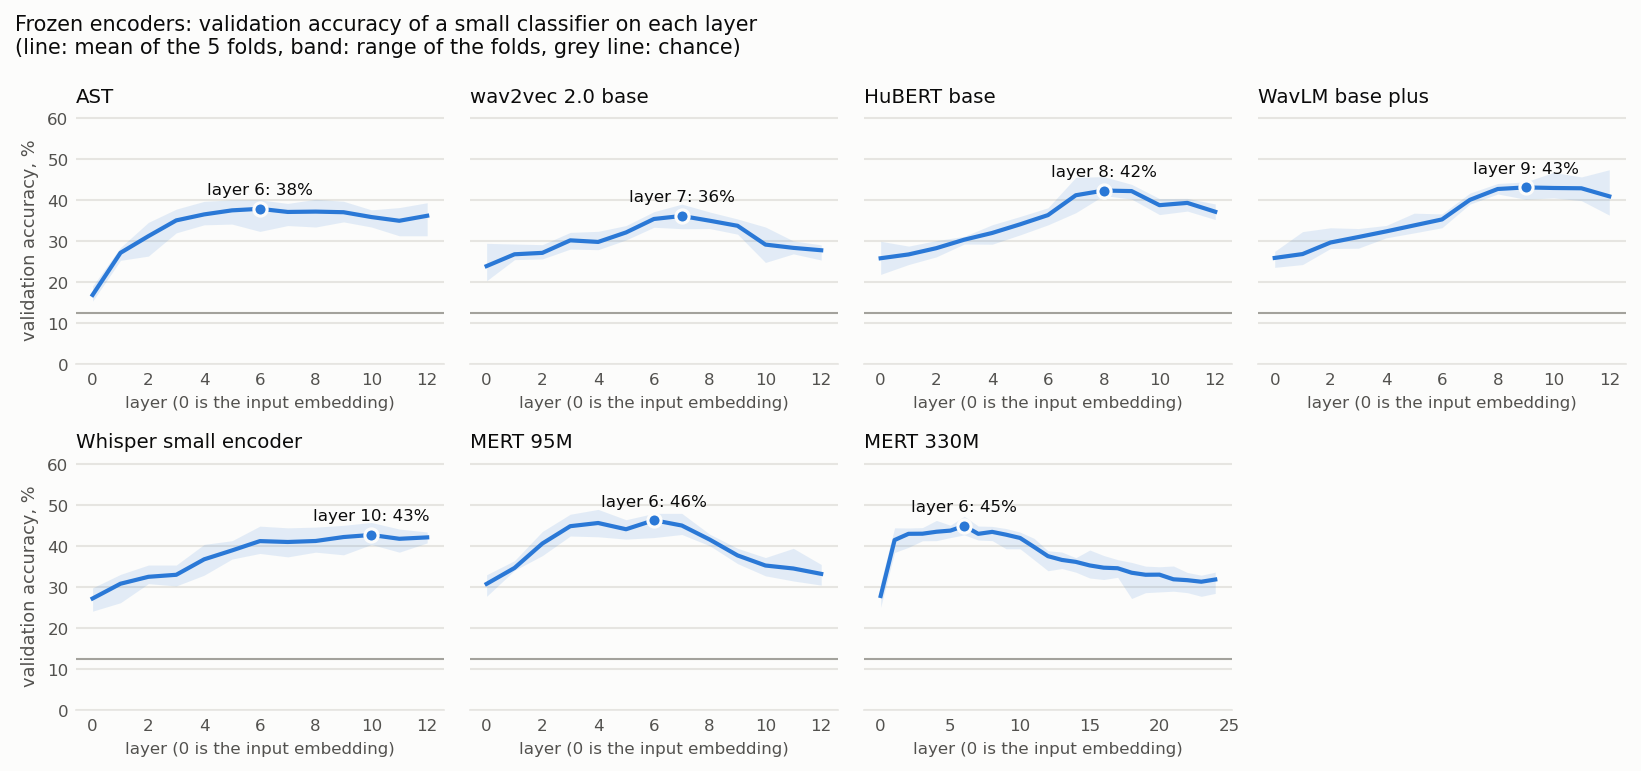

In [13]:
with open(os.path.join(RESULTS, "layer_sweep.json")) as handle:
    layers = json.load(handle)
_ = report.figure_layers(layers)
show(plain[plain["family"].isin(["frozen encoder", "fine-tuned encoder"])])

The hypothesis of Level 4, that transfer learning achieves the highest accuracy, is not confirmed. The best frozen encoder is the music model MERT 95M with 43.3%, ahead of the speech models (40.6% for HuBERT, 39.9% for WavLM, 40.0% for Whisper) and of AST (36.1% with the best layer, 32.3% with the classification token of the last layer) (Table 24). The larger MERT 330M is not better than MERT 95M. In every encoder a middle layer is better than the last one (Figure 6). Fine-tuning the whole MERT 95M gives 59.4%, +16.1 points against its frozen form (+13.5 to +18.6), so the second point of "Why Transfer Learning?" holds: fine-tuning makes much more of the pretrained model than a classifier on its frozen features. All of these still stay below the 1D CNN on 14 chroma channels with random key changes (65.2% without augmentation of the audio), a network of 96,936 parameters against the 95 million of MERT 95M.

## 6.7 Variants for Poor Data

For XGBoost on the aggregated features and for the classifier on each frozen encoder:

- two stages: a first model predicts hum or whistle, then a separate song model per type is used,
- per-type standardisation: one song model, but the inputs of hums and of whistles are standardised separately.

For the classifier on each frozen encoder also:

- mixup with label smoothing,
- pruning: the training recordings that a model trained on other training participants finds least recognisable are left out. The share (0, 10, 20 or 30%) is chosen on the validation fold.

**Table 25.** A separate treatment of hums and whistles. Difference to the plain model in points of clip accuracy, with the 95% interval.

| Plain model | Plain, % | Two stages | Per-type standardisation |
|---|---|---|---|
| XGBoost, aggregate statistics | 36.6 | -2.6 (-4.3 to -0.8) | +0.9 (-0.3 to +2.1) |
| AST, last token | 32.3 | -0.7 (-1.8 to +0.4) | +0.5 (-0.3 to +1.4) |
| AST, best layer | 36.1 | -1.9 (-3.1 to -0.8) | -0.1 (-1.0 to +0.8) |
| wav2vec 2.0 | 34.9 | -1.9 (-3.1 to -0.7) | +0.1 (-0.8 to +0.9) |
| HuBERT | 40.6 | -3.2 (-4.7 to -1.7) | -0.6 (-1.4 to +0.2) |
| WavLM | 39.9 | -3.3 (-4.6 to -2.0) | +0.8 (0.0 to +1.6) |
| Whisper | 40.0 | -1.0 (-2.4 to +0.4) | -0.1 (-1.1 to +0.9) |
| MERT 95M | 43.3 | -3.1 (-4.3 to -1.9) | +0.7 (-0.1 to +1.4) |
| MERT 330M | 41.9 | -3.3 (-4.7 to -2.0) | +0.2 (-0.7 to +1.1) |

A first model tells hums from whistles almost without error (99.3% of the test clips for XGBoost on aggregated features). A separate song model per type is nevertheless worse than one model in all 9 rows (from -3.3 to -0.7 points), and in 7 of them the interval excludes zero (Table 25). Each song model sees half of the data, and that costs more than the separation gains. Standardising the inputs per type instead keeps all the data in one model and changes little (from -0.6 to +0.9 points, the interval excludes zero only for WavLM).

**Table 26.** Methods for noisy labels on the classifier on frozen embeddings. Difference to the plain model in points of clip accuracy, with the 95% interval.

| Plain model | Plain, % | Mixup, label smoothing | Pruning |
|---|---|---|---|
| AST, last token | 32.3 | -0.8 (-1.7 to +0.1) | -0.2 (-0.7 to +0.3) |
| AST, best layer | 36.1 | -0.8 (-1.7 to +0.2) | -0.3 (-0.8 to +0.3) |
| wav2vec 2.0 | 34.9 | -1.3 (-2.2 to -0.5) | -0.2 (-0.8 to +0.3) |
| HuBERT | 40.6 | -1.6 (-2.6 to -0.7) | -0.3 (-0.8 to +0.1) |
| WavLM | 39.9 | +0.3 (-0.7 to +1.2) | -0.3 (-0.7 to +0.1) |
| Whisper | 40.0 | -0.9 (-2.0 to +0.1) | -0.1 (-0.6 to +0.3) |
| MERT 95M | 43.3 | +0.2 (-0.9 to +1.2) | -0.4 (-0.8 to 0.0) |
| MERT 330M | 41.9 | +2.1 (+1.0 to +3.3) | -0.2 (-0.4 to 0.0) |

In [14]:
rows = []
for name in sorted(predictions):
    if name.count("__") != 2 or name.startswith("ensemble"):
        continue
    model, inputs, variant, arm = report.split_name(name)
    if variant not in ("two_stage", "kind_norm", "mixup", "pruned"):
        continue
    base = f"{model}__{inputs}__{arm}"
    a, groups = report.correct_share(predictions[name]["proba"], clips)
    b, _ = report.correct_share(predictions[base]["proba"], clips)
    difference, low, high = evaluation.bootstrap_difference(a, b, groups)
    rows.append({"plain experiment": report._short(base), "variant": report.VARIANT_LABELS[variant],
                 "plain": round(100 * b.mean(), 1), "variant accuracy": round(100 * a.mean(), 1),
                 "difference": round(100 * difference, 1), "interval": f"{100 * low:+.1f} to {100 * high:+.1f}"})
variants = pd.DataFrame(rows)
display(variants.groupby("variant")["difference"].agg(["count", "mean", "min", "max"]).round(1))
variants

,count,mean,min,max
variant,,,,
least recognisable training recordings removed,8,-0.2,-0.4,-0.1
mixup and label smoothing,8,-0.4,-1.6,2.1
standardised per type,9,0.3,-0.6,0.9
two stages: hum or whistle first,9,-2.3,-3.3,-0.7


,plain experiment,variant,plain,variant accuracy,difference,interval
0,"MLP, AST (last token)",standardised per type,32.3,32.8,0.5,-0.3 to +1.4
1,"MLP, AST (best layer)",standardised per type,36.1,36.0,-0.1,-1.0 to +0.8
2,"MLP, AST (best layer)",mixup and label smoothing,36.1,35.3,-0.8,-1.7 to +0.2
3,"MLP, AST (best layer)",least recognisable training recordings removed,36.1,35.8,-0.3,-0.8 to +0.3
4,"MLP, AST (best layer)",two stages: hum or whistle first,36.1,34.1,-1.9,-3.1 to -0.8
5,"MLP, AST (last token)",mixup and label smoothing,32.3,31.5,-0.8,-1.7 to +0.1
6,"MLP, AST (last token)",least recognisable training recordings removed,32.3,32.0,-0.2,-0.7 to +0.3
7,"MLP, AST (last token)",two stages: hum or whistle first,32.3,31.6,-0.7,-1.8 to +0.4
8,"MLP, HuBERT base",standardised per type,40.6,39.9,-0.6,-1.4 to +0.2
9,"MLP, HuBERT base",mixup and label smoothing,40.6,38.9,-1.6,-2.6 to -0.7


Pruning the least recognisable training recordings helps no classifier (differences from -0.4 to -0.1 points) (Table 26). Mixup with label smoothing has no consistent effect: the differences range from -1.6 to +2.1 points, and the interval excludes zero for 3 of the 8 classifiers (a loss for wav2vec 2.0 and HuBERT and a gain for MERT 330M). The labels of these data are correct. What is poor is the performance, and removing the poorest training performances removes the examples that resemble the test data most.

## 6.8 Ensemble Model

### Why Ensemble?

Different models capture different aspects of the data:
- **XGBoost (aggregated)**: Global statistical patterns
- **XGBoost (segments)**: Coarse temporal structure
- **CNN (melody_full)**: Fine-grained temporal patterns

By combining their predictions through **averaging of the class probabilities**, we can use the strengths of each approach.

### Models Included

Four ensembles are reported (Table 27). Two have members that were fixed before any result was seen:
1. XGBoost with aggregated features, XGBoost with segment-based features and the 1D CNN on `melody_full` (three models on the frame-level features)
2. The same three with the LSTM, XGBoost on contour statistics and the classifier on AST (six models over all inputs of the first part)

Two more are defined by validation accuracy alone: one takes the best model of every family (hand-made features including the chroma, pitch contour, frozen encoder, fine-tuned encoder, melody matching), the other the best models of the two families with the highest validation accuracy.

**Table 27.** Ensembles (mean of the class probabilities of the members).

| Model | Input | Variant | Clips, % | 95% interval | Recordings, % | 95% interval |
|---|---|---|---|---|---|---|
| Ensemble | three models on the frame-level features | plain | 50.8 ± 0.6 | 47.6 to 53.9 | 57.4 ± 1.6 | 53.8 to 61.1 |
| Ensemble | six models, all inputs | plain | 51.9 ± 0.5 | 48.9 to 55.0 | 58.1 ± 0.8 | 54.4 to 62.0 |
| Ensemble | best model of every family by validation accuracy | plain | 75.6 ± 0.3 | 72.7 to 78.4 | 83.1 ± 0.6 | 80.0 to 86.1 |
| Ensemble | best models of the two families with the highest validation accuracy | plain | 75.1 ± 0.2 | 72.4 to 77.9 | 82.8 ± 0.3 | 79.9 to 85.8 |

In [15]:
print("best model of every family by validation accuracy:")
for group, name in report.best_members(RESULTS).items():
    print("  %-22s %s" % (group, name))
print("the two strongest families:", ", ".join(report.best_members(RESULTS, top=2).values()))
show(models[models["model"] == "Ensemble"])

best model of every family by validation accuracy:


  fine-tuned encoder     finetune__mert__none
  frozen encoder         mlp__mert_pruned__none
  hand-made features     cnn1d__melody_full_transpose__heavy
  melody matching        knn__contour_dtw__none
  pitch contour          cnn1d__contour_wide__none


the two strongest families: cnn1d__melody_full_transpose__heavy, cnn1d__contour_wide__none


,model,input,variant,clip,± std,interval,recording,validation,train
0,Ensemble,best model of every family by validation accuracy,plain,75.6,0.3,72.7 to 78.4,83.1,NaN,NaN
1,Ensemble,best models of the two families with the highest validation accuracy,plain,75.1,0.2,72.4 to 77.9,82.8,NaN,NaN
2,Ensemble,"six models, all inputs",plain,51.9,0.5,48.9 to 55.0,58.1,NaN,NaN
3,Ensemble,three models on the frame-level features,plain,50.8,0.6,47.6 to 53.9,57.4,NaN,NaN


### Ensemble: Conclusions

**Did ensemble help in our case?**

Yes, when the members are strong and different. Members chosen by validation accuracy: for the best model of every family `finetune__mert__none` (fine-tuned encoder), `mlp__mert_pruned__none` (frozen encoder), `cnn1d__melody_full_transpose__heavy` (hand-made features), `knn__contour_dtw__none` (melody matching), `cnn1d__contour_wide__none` (pitch contour), for the two strongest families `cnn1d__melody_full_transpose__heavy` and `cnn1d__contour_wide__none`. The best network on the chroma and the best network on the pitch contour make different errors: their average reaches 75.1% of the clips and 82.8% of the recordings. Adding the best models of the other families to the average gives 75.6% and 83.1%.

The improvement margin depends on how diverse and accurate the base models are. If all models make similar errors (e.g., confusing the same pair of songs), ensemble won't help much: the two ensembles of the first part, whose members share the same hand-made features, stay at 50.8% and 51.9%.

## 6.9 Final Results Summary

The single model with the highest validation accuracy is `cnn1d__melody_full_transpose__heavy` (1D CNN, chroma, chroma difference, onset, tempo (26 channels), random key changes in training, combined augmentation, four copies per clip): 71.3% ± 0.5 of the clips (68.4 to 74.1) and 80.1% ± 1.1 of the recordings (77.0 to 83.1), with a validation accuracy of 72.6%. It was selected on the validation folds, so its test accuracy is not the largest number of a search over the test folds (see also section 7.2). Figure 7 shows its errors by song, and Figure 8 the experiments without augmentation side by side.

![Confusion matrix of the final model](../figures/confusion_cnn1d__melody_full_transpose__heavy.png)

**Figure 7.** Confusion matrix of the final model on the clips: for the clips of each song (rows), the share assigned to every song (columns), all seeds pooled.

![Clip and recording accuracy of the experiments without augmentation](../figures/accuracy_by_model.png)

**Figure 8.** Clip and recording accuracy of the experiments without augmentation and without a variant. The dashed line is the random baseline.

final model: cnn1d__melody_full_transpose__heavy


,model,input,variant,clip,± std,interval,recording,validation,train
0,1D CNN,"chroma, chroma difference, onset, tempo (26 channels)","random key changes in training, combined augmentation, four copies per clip",71.3,0.5,68.4 to 74.1,80.1,72.6,89.5


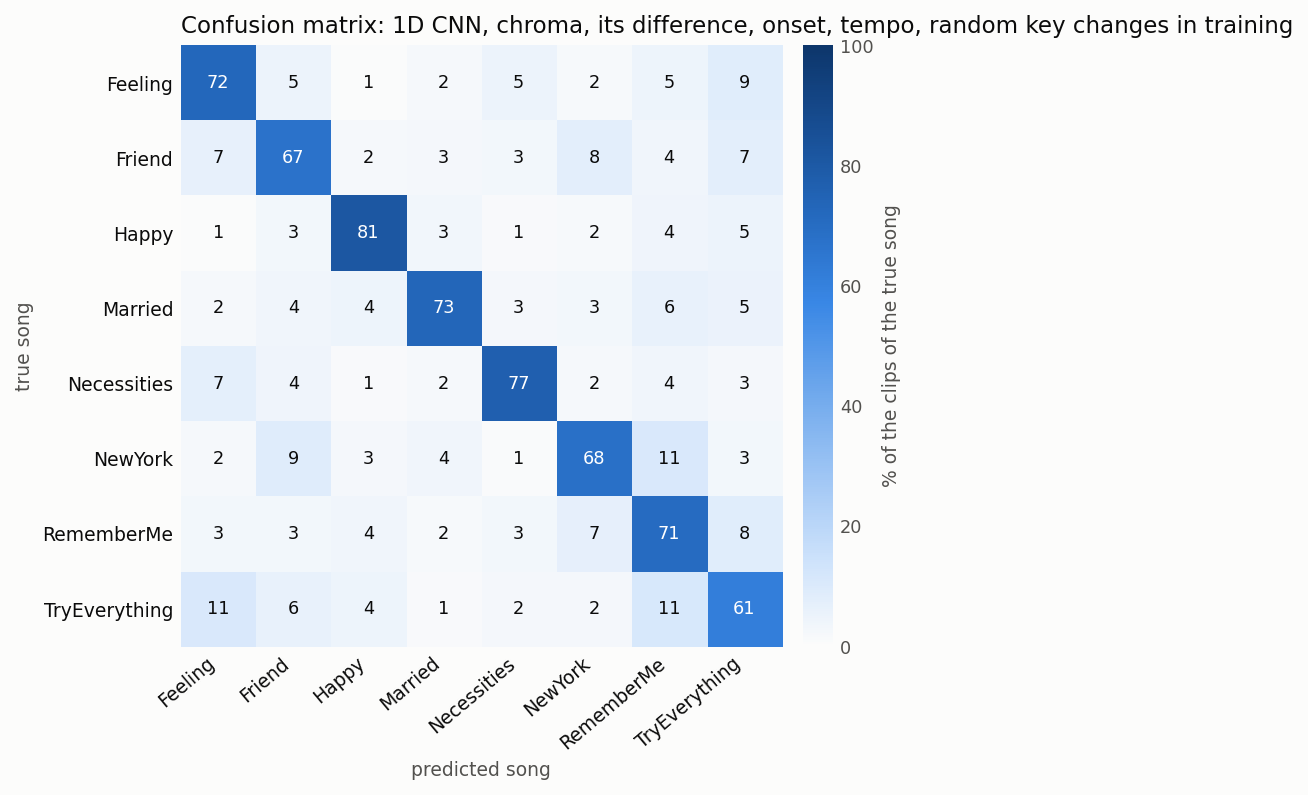

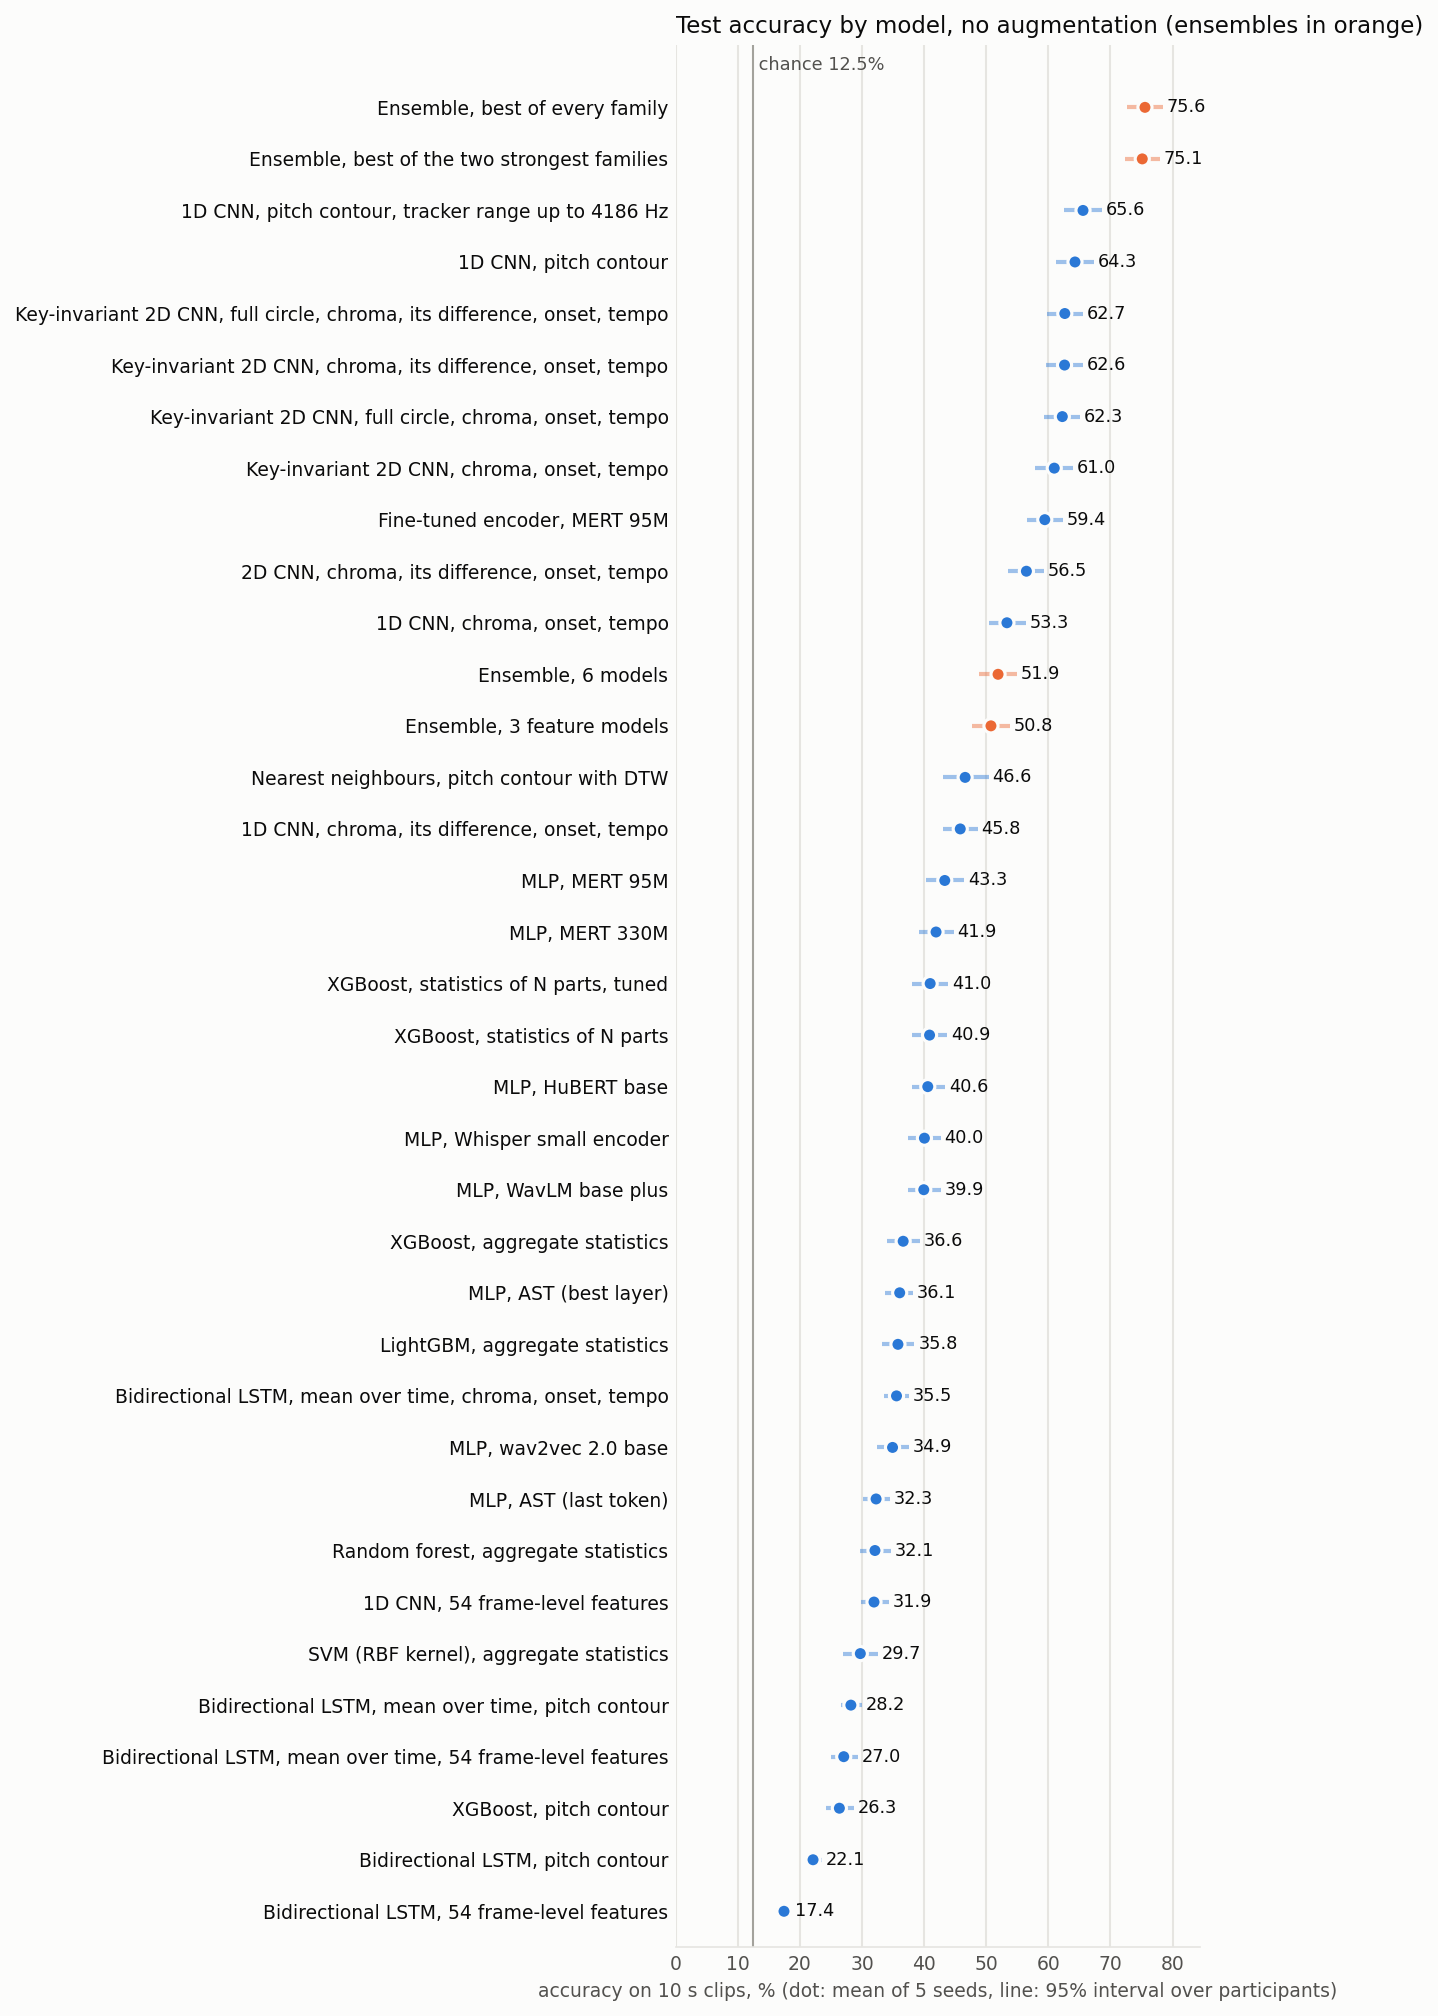

In [16]:
final = report.final_model(models)
print("final model:", final)
display(show(models[models["experiment"] == final]))
_ = report.figure_confusion(report.confusion(predictions[final]["proba"], clips), "Confusion matrix: " + report._short(final))
_ = report.figure_overview(models)

### Hummed and whistled clips, full and padded clips

**Table 28.** Clip accuracy on the hummed and on the whistled clips.

| Model | Hummed clips, % | Whistled clips, % |
|---|---|---|
| XGBoost, mean and std over time (109 numbers) | 39.0 | 34.1 |
| XGBoost, mean and std in N parts of the clip, selected | 42.9 | 38.8 |
| 1D CNN, chroma, chroma difference, onset, tempo (26 channels) | 48.5 | 43.0 |
| 1D CNN, chroma, chroma difference, onset, tempo (26 channels), random key changes in training | 68.7 | 63.1 |
| Key-invariant 2D CNN, chroma, chroma difference, onset, tempo (26 channels) | 66.2 | 58.9 |
| 1D CNN, pitch contour | 71.2 | 57.2 |
| 1D CNN, pitch contour, tracker range up to 4186 Hz | 71.8 | 59.2 |
| Nearest neighbours, pitch contour, DTW to the training recordings | 58.7 | 34.2 |
| MLP on frozen encoder, MERT 95M | 44.6 | 42.0 |
| Fine-tuned encoder, MERT 95M | 59.9 | 59.0 |
| 1D CNN, chroma, chroma difference, onset, tempo (26 channels), random key changes in training, combined augmentation, four copies per clip | 74.3 | 68.1 |
| Ensemble, best models of the two families with the highest validation accuracy | 79.1 | 71.1 |

![Clip accuracy on hummed and on whistled clips](../figures/hum_and_whistle.png)

**Figure 9.** The numbers of Table 28 as bars.

Hums are recognised better than whistles by every model of Table 28 (Figure 9). The gap is largest for the models on the pitch contour: 58.7% against 34.2% for the melody matching and 71.2% against 57.2% for the contour CNN. The wider range of the tracker moves the whistled clips of the contour CNN to 59.2% (hums 71.8%), so the range explains only a small part of the gap. The fine-tuned encoder, which hears the audio itself and not a pitch track, has almost no gap (59.9% against 59.0%).

**Table 29.** Clip accuracy on the full 10-second clips and on the padded last clip of a recording.

| Model | Full clips, % | Padded clips, % |
|---|---|---|
| XGBoost, mean and std over time (109 numbers) | 37.7 | 33.8 |
| XGBoost, mean and std in N parts of the clip, selected | 42.8 | 35.8 |
| 1D CNN, chroma, chroma difference, onset, tempo (26 channels) | 47.6 | 41.2 |
| 1D CNN, chroma, chroma difference, onset, tempo (26 channels), random key changes in training | 68.4 | 59.8 |
| Key-invariant 2D CNN, chroma, chroma difference, onset, tempo (26 channels) | 64.2 | 58.4 |
| 1D CNN, pitch contour | 65.9 | 60.2 |
| 1D CNN, pitch contour, tracker range up to 4186 Hz | 66.9 | 62.3 |
| Nearest neighbours, pitch contour, DTW to the training recordings | 48.2 | 42.4 |
| MLP on frozen encoder, MERT 95M | 45.0 | 39.0 |
| Fine-tuned encoder, MERT 95M | 60.8 | 55.8 |
| 1D CNN, chroma, chroma difference, onset, tempo (26 channels), random key changes in training, combined augmentation, four copies per clip | 73.2 | 66.4 |
| Ensemble, best models of the two families with the highest validation accuracy | 76.9 | 70.6 |

,experiment,full,padded
0,xgboost__aggregate__none,37.7,33.8
1,cnn1d__melody_full_transpose__none,68.4,59.8
2,cnn1d__contour__none,65.9,60.2
3,cnn1d__contour_wide__none,66.9,62.3
4,knn__contour_dtw__none,48.2,42.4
5,mlp__mert__none,45.0,39.0
6,cnn1d__melody_full_transpose__heavy,73.2,66.4
7,ensemble__top2,76.9,70.6


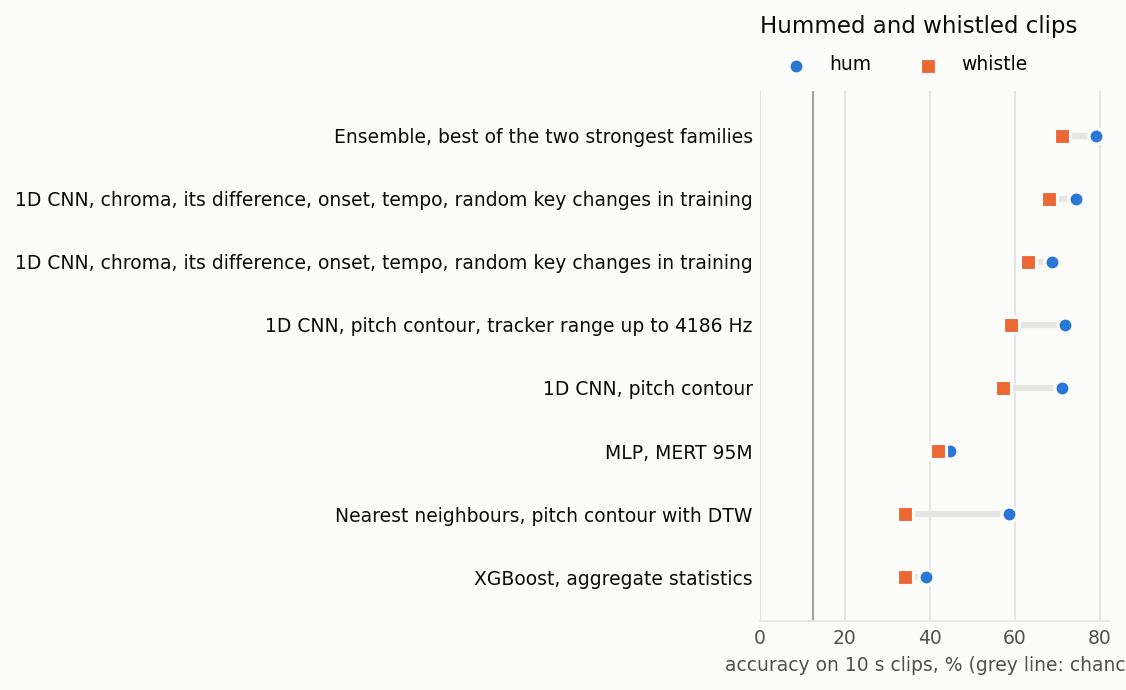

In [17]:
shown = ["xgboost__aggregate__none", "cnn1d__melody_full_transpose__none", "cnn1d__contour__none", "cnn1d__contour_wide__none",
         "knn__contour_dtw__none", "mlp__mert__none", final, "ensemble__top2"]
kinds = report.kind_table(clips, predictions, shown)
_ = report.figure_kinds(kinds)
padded = report.padded_table(clips, predictions, shown)
padded[["full", "padded"]] = (100 * padded[["full", "padded"]]).round(1)
padded

The recordings of one song are shorter than the others (a median of 17.5 s for NewYork against 19.6 s for all recordings), so the amount of padding carries a trace of the song. No model profits from it visibly. The padded clip is harder than a full clip for all 12 models (Table 29).

## 6.10 Checks of the Protocol

**Table 30.** Clip accuracy under the protocol and under three deliberately changed protocols.

| Model | Participant-disjoint folds (the protocol), % | Labels shuffled, % | Recordings split at random, % | Clips split at random, % |
|---|---|---|---|---|
| 1D CNN, pitch contour | 64.3 | 12.3 ± 0.6 | 63.2 ± 0.4 | 75.6 ± 0.7 |
| 1D CNN, chroma, its difference, onset, tempo, random key changes in training | 66.0 | 11.9 ± 1.1 | 63.5 ± 0.6 | 77.8 ± 0.5 |
| MLP, AST (last token) | 32.3 | 12.4 ± 1.1 | 27.4 ± 0.5 | 69.6 ± 0.6 |
| XGBoost, aggregate statistics | 36.6 | 11.7 ± 0.4 | 32.7 ± 0.3 | 56.8 ± 0.4 |

In [18]:
checks = report.checks_table(clips, predictions)
display(pd.DataFrame({"model": checks["model"], "check": checks["check"], "clip": (100 * checks["clip_accuracy"]).round(1),
                      "± std": (100 * checks["clip_std"]).round(1), "recording": (100 * checks["recording_accuracy"]).round(1),
                      "clip, participant folds": (100 * checks["clip_accuracy_participant_folds"]).round(1)}))
with open(os.path.join(RESULTS, "duplicate_check.json")) as handle:
    duplicates = json.load(handle)
print("search for one performance under two participant numbers (the same audio gives a spread of 0 semitones):")
for group in ("different_participants", "same_participant_other_recording"):
    item = duplicates[group]
    print("  %-34s %9d pairs of clips, smallest spread %.2f semitones, pairs below 0.1 semitones: %d" % (
        group, item["pairs_compared"], item["smallest_spread_semitones"], item["pairs_below_a_tenth_of_a_semitone"]))

,model,check,clip,± std,recording,"clip, participant folds"
0,"1D CNN, pitch contour",clips split at random (recordings on both sides),75.6,0.7,86.7,64.3
1,"1D CNN, pitch contour",recordings split at random (participants on both sides),63.2,0.4,72.0,64.3
2,"1D CNN, pitch contour",training labels shuffled,12.3,0.6,11.8,64.3
3,"1D CNN, chroma, its difference, onset, tempo, random key changes in training",clips split at random (recordings on both sides),77.8,0.5,88.6,66.0
4,"1D CNN, chroma, its difference, onset, tempo, random key changes in training",recordings split at random (participants on both sides),63.5,0.6,72.0,66.0
5,"1D CNN, chroma, its difference, onset, tempo, random key changes in training",training labels shuffled,11.9,1.1,11.4,66.0
6,"MLP, AST (last token)",clips split at random (recordings on both sides),69.6,0.6,82.5,32.3
7,"MLP, AST (last token)",recordings split at random (participants on both sides),27.4,0.5,30.2,32.3
8,"MLP, AST (last token)",training labels shuffled,12.4,1.1,11.8,32.3
9,"XGBoost, aggregate statistics",clips split at random (recordings on both sides),56.8,0.4,67.6,36.6


search for one performance under two participant numbers (the same audio gives a spread of 0 semitones):
  different_participants               3759857 pairs of clips, smallest spread 0.32 semitones, pairs below 0.1 semitones: 0
  same_participant_other_recording       16602 pairs of clips, smallest spread 0.31 semitones, pairs below 0.1 semitones: 0


With shuffled training labels all four models fall to the random baseline of 12.5% (Table 30), so a model reaches its score through the training labels and through nothing else in the pipeline. With clips split at random, so that overlapping clips of one recording fall on both sides, every model gains between 11.3 and 37.4 points. This is the size of the error that a split by clips would have made. With recordings split at random, so that only the participant is shared, no model gains: no participant of this sample recorded the same song twice (0 of 800 pairs of participant and song), so the other recordings of a test participant in the training set are all of other songs, and a model that recognises the voice is led to the wrong song. This check can therefore not show that the participants are kept apart. That follows from the folds themselves (`results/recordings.csv` has no participant in two folds).

The same performance under two participant numbers would defeat a split by participants. `scripts/check_duplicates.py` compared the pitch tracks of 3,759,857 pairs of clips of different participants. The same audio gives a spread of the pitch difference of 0 semitones, also after a shift of the pitch as a whole. The smallest spread found is 0.32 semitones, and 0 pairs are below 0.1.

**Table 31.** The choices between experiments, made once for all folds from the mean validation accuracy (as reported in sections 6.8 and 6.9) and made for every test fold from the validation fold of the same split alone.

| Choice | Clips, chosen once, % | Clips, chosen per fold, % | Recordings, chosen once, % | Recordings, chosen per fold, % |
|---|---|---|---|---|
| Final model | 71.3 | 71.2 | 80.1 | 79.9 |
| Two strongest families | 75.1 | 74.9 | 82.8 | 82.5 |
| Best model of every family | 75.6 | 76.0 | 83.1 | 83.3 |

In [19]:
selection = report.selection_check(clips, predictions)
for column in selection.columns[selection.columns.str.contains("accuracy")]:
    selection[column] = (100 * selection[column]).round(1)
for row in selection.itertuples():
    print(row.choice, "chosen per fold:")
    for fold, names in enumerate(row.chosen_per_fold.split(" | ")):
        print("   fold", fold, names)
selection.drop(columns="chosen_per_fold")

final model chosen per fold:
   fold 0 cnn1d__melody_full_transpose__heavy
   fold 1 cnn1d__melody_full_transpose__heavy
   fold 2 cnn1d__melody_full_transpose__heavy
   fold 3 cnn1d__melody_full_transpose__strong
   fold 4 cnn1d__melody_full_transpose__heavy
two strongest families chosen per fold:
   fold 0 cnn1d__contour_wide__none + cnn1d__melody_full_transpose__heavy
   fold 1 cnn1d__contour_wide__none + cnn1d__melody_full_transpose__heavy
   fold 2 cnn1d__contour_wide__none + cnn1d__melody_full_transpose__heavy
   fold 3 cnn1d__contour_wide__none + cnn1d__melody_full_transpose__strong
   fold 4 cnn1d__contour_wide__none + cnn1d__melody_full_transpose__heavy
best model of every family chosen per fold:
   fold 0 cnn1d__contour_wide__none + cnn1d__melody_full_transpose__heavy + finetune__mert__none + knn__contour_dtw__none + mlp__mert__none
   fold 1 cnn1d__contour_wide__none + cnn1d__melody_full_transpose__heavy + finetune__mert__none + knn__contour_dtw__none + mlp__mert_mixup__none

,choice,clip_accuracy_all_splits,recording_accuracy_all_splits,clip_accuracy_own_split,recording_accuracy_own_split
0,final model,71.3,80.1,71.2,79.9
1,two strongest families,75.1,82.8,74.9,82.5
2,best model of every family,75.6,83.1,76.0,83.3


The final model and the members of the two ensembles were chosen once, with validation numbers to which every fold contributed. Table 31 repeats these choices strictly per test fold. The two ways differ by at most 0.4 points (the choice made once is the higher one in 4 of the 6 comparisons), which is of the size of the spread over the seeds.

## 6.11 Trained Twice

Three feature models and two networks were trained a second time on another machine with other GPUs, from the same extracted features and with the same seeds (Table 32). The second training of two more networks stopped with a GPU error of that machine and is not reported.

**Table 32.** Experiments trained a second time on another machine. "Same predicted song" is the share of all clips and seeds for which both runs predict the same song.

| Experiment | Clips, published run, % | Clips, second run, % | Same predicted song, % of clips and seeds | Largest difference of a probability |
|---|---|---|---|---|
| `cnn1d__melody_full__none` | 45.8 | 45.8 | 100.0 | 0.0000 |
| `cnn1d__melody_full__strong` | 62.7 | 62.7 | 99.2 | 0.9226 |
| `lightgbm__aggregate__conservative` | 35.9 | 35.9 | 100.0 | 0.0000 |
| `xgboost__aggregate__none` | 36.6 | 36.6 | 100.0 | 0.0000 |
| `xgboost__temporal__none` | 40.9 | 40.9 | 100.0 | 0.0000 |

In [20]:
repeated = report.repeat_table(clips, predictions, RESULTS)
for column in ("clip_accuracy", "clip_accuracy_repeated", "same_prediction_share"):
    repeated[column] = (100 * repeated[column].astype(float)).round(1)
display(repeated)
rows = []
for name in plain["experiment"]:
    summary = evaluation.summarise(predictions[name]["proba"], clips, n_boot=200)["clip"]
    rows.append({"experiment": report._short(name), "seeds": len(summary["per_seed"]),
                 "lowest seed": round(100 * min(summary["per_seed"]), 1), "highest seed": round(100 * max(summary["per_seed"]), 1),
                 "lowest fold": round(100 * min(summary["per_fold"]), 1), "highest fold": round(100 * max(summary["per_fold"]), 1)})
print("spread of the clip accuracy over seeds and over test folds:")
pd.DataFrame(rows)

,experiment,clip_accuracy,clip_accuracy_repeated,same_prediction_share,max_probability_difference
0,cnn1d__melody_full__none,45.8,45.8,100.0,0.000000
1,cnn1d__melody_full__strong,62.7,62.7,99.2,0.922577
2,lightgbm__aggregate__conservative,35.9,35.9,100.0,0.000000
3,xgboost__aggregate__none,36.6,36.6,100.0,0.000000
4,xgboost__temporal__none,40.9,40.9,100.0,0.000000


spread of the clip accuracy over seeds and over test folds:


,experiment,seeds,lowest seed,highest seed,lowest fold,highest fold
0,"Ensemble, best of every family",5,75.0,75.9,72.8,79.7
1,"Ensemble, best of the two strongest families",5,75.0,75.4,73.1,78.9
2,"1D CNN, pitch contour, tracker range up to 4186 Hz",5,64.2,66.7,63.5,68.7
3,"1D CNN, pitch contour",5,63.7,65.1,62.5,67.0
4,"Key-invariant 2D CNN, full circle, chroma, its difference, onset, tempo",5,61.9,62.9,60.6,67.1
5,"Key-invariant 2D CNN, chroma, its difference, onset, tempo",5,61.6,63.3,60.3,67.3
6,"Key-invariant 2D CNN, full circle, chroma, onset, tempo",5,60.8,64.3,59.5,67.2
7,"Key-invariant 2D CNN, chroma, onset, tempo",5,60.4,61.7,58.2,65.1
8,"Fine-tuned encoder, MERT 95M",5,58.5,60.4,56.3,65.1
9,"2D CNN, chroma, its difference, onset, tempo",5,55.1,57.2,51.8,59.9


The feature models and the 1D CNN without augmentation give exactly the same predictions again. The 1D CNN with the strong arm does not: a few of its 25 trainings took another course, the predicted song is the same for 99.2% of the clips and seeds, and the accuracy differs by 0.07 points, which is less than its spread over the seeds. Networks are therefore repeatable here in most runs but not in all, and differences of a tenth of a point between two networks mean nothing.

# 7 Conclusions

## 7.1 Summary of Findings

Key findings:

1. **Classical ML models** (Random Forest, XGBoost, SVM) with aggregated audio features provided a solid baseline, achieving 29.7% to 36.6% test accuracy, and 40.9% with segment-based features (Table 10, Table 14). Hyperparameter tuning changes nothing.

2. **CNN on feature sequences** captured temporal patterns better, achieving 53.3% on the chroma with onset strength and tempo, against 31.9% on all 54 features (Table 16). The input matters more than the model.

3. **Ensemble methods** combining multiple models showed the best performance: 75.1% of the clips and 82.8% of the recordings for the average of the best chroma network and the best contour network (Table 27).

4. **Feature importance analysis** revealed that the tempo and the onset strength were the most used features of the random forest. The tonnetz and chroma features follow at a small distance, about level with the MFCC (Table 9).

The experiments beyond the four levels add the following:

5. **The key is the main obstacle.** Rotating the pitch classes at random during training raises the 1D CNN from 45.8% to 66.0% without any change of the audio, and a network that is invariant to the rotation by construction reaches 62.6% without any augmentation (Table 19). The pitch contour, which has no key by definition, gives 64.3% with the same 1D CNN and only 26.3% when it is reduced to 19 summary numbers (Table 21).

6. **Augmentation of the audio helps the network and not the trees.** For the 1D CNN the conservative arm adds 9.8 points and the strong arm 16.9. Part of this is only the larger number of training clips per epoch: repeating unchanged clips already adds 3.5 points (Table 17). For the four models on aggregated features no arm changes the accuracy by more than 2.2 points (Table 11).

7. **The tempo is not the obstacle.** Random changes of tempo during training change the plain 1D CNN by +0.7 points and the key-invariant CNN by -0.9 points on the chroma with differences (Table 19), and lower the contour network by 2.7 points (Table 21).

8. **Pretrained encoders stay behind the small networks.** The best frozen encoder is the music model MERT 95M with 43.3%, ahead of the speech models (40.6% for HuBERT) and of AST (36.1%). Fine-tuning it helps a lot (59.4%) and still leaves it below the 1D CNN on 14 chroma channels with random key changes (65.2%) (Table 24).

9. **A separate song model for hums and for whistles is worse than one model.** The type is predicted correctly for 99.3% of the clips, but each song model then sees half of the data, and XGBoost loses 2.6 points (Table 25).

10. **Methods for noisy labels do not fit these data.** Pruning the least recognisable training recordings helps no classifier, and mixup with label smoothing has no consistent effect (Table 26). The labels are correct, the performances are poor, and removing the poorest training performances removes the examples that resemble the test data most.

11. **Averaging helps twice.** The clips of one recording averaged give 80.1% instead of 71.3% for the final model, and the average of the two strongest families adds to that (Table 27).

12. **The split decides what the number means.** With clips split at random, so that overlapping clips of one recording fall on both sides, XGBoost on aggregated features scores 56.8% instead of 36.6% and the classifier on AST 69.6% instead of 32.3%. With shuffled training labels every checked model falls to the random baseline (Table 30).

## 7.2 Challenges and Limitations

1. **Limited data**: 100 samples per class is insufficient for deep learning to reach its full potential.

2. **High variability**: Different people sing at different tempos, pitches, and with varying accuracy.

3. **Modality differences**: Humming and whistling have very different acoustic properties.

Limitations of the measurement itself:

- Every clip has been test data. Settings and the final model were chosen on validation folds only, but the later experiments (the key-invariant models, the combined augmentation, the wider range of the pitch tracker, the choice of what to try next) were designed after the test accuracy of the earlier ones was known. The numbers are therefore not an estimate from untouched data, and a new set of recordings would be needed for one.
- The validation accuracy of a model is the highest value over its epochs or over its settings, so it is biased upwards, and an experiment in which more settings are chosen on the validation fold has an advantage when experiments are ranked by it. The final model is the best of many by this value. Every fold is the validation fold of one split and the test fold of another, so this choice is not fully separate from the test data. Chosen strictly per fold the result is the same within 0.4 points (Table 31).
- One division of the participants into folds (seed 0). The intervals describe the resampling of participants, not another choice of folds.
- Eight songs, one collection. Nothing here says how the methods behave with hundreds of songs, with songs that are absent from the training data, or with recordings made in another way.
- One clip of every recording is padded with zeros (5 to 10 s of audio). Padded clips are counted like the others, and they are harder (Table 29).
- One participant number is taken to be one person. Copies of a performance under two numbers were looked for and not found, but two numbers of one person who performed twice cannot be seen in the data.
- The pretrained encoders were trained on outside audio that may contain the eight songs. This concerns the rows of Table 24 only.
- Augmented training sets are larger, and early stopping counts epochs. The control with repeated clips separates the two effects for one model and one arm only.
- The encoder layer, the number of temporal segments and the learning rate of the fine-tuning were chosen with the first seed and then used for all seeds.
- Only one encoder was fine-tuned, and without augmentation.
- The networks are small and were not tuned beyond what is listed here. The LSTM in particular was tried in two forms only.

## 7.3 Suggestions for Improvement

1. **Data augmentation**: Time stretching, pitch shifting and noise addition are measured here for the small networks. The next step is the same augmentation for the fine-tuned encoder and for the contour network.

2. **Transfer learning**: Seven pre-trained audio models are compared here. A pitch tracker trained for whistles and hums could close the gap between the two modalities on the pitch contour (Table 28).

3. **Sequence models**: The LSTM of this study stays behind the CNN. A recurrent or attention model on the pitch contour, tuned with the same care as the CNN, is still untested.

4. **More data**: Collect more diverse recordings per song, and a set of recordings that is used once, for a final test.

## Acknowledgements

The recordings are part of the MLEnd Hums and Whistles II data set of the MLEnd Datasets project (Jesús Requena Carrión and Nikesh Bajaj, School of Electronic Engineering and Computer Science, Queen Mary University of London, [mlenddatasets.github.io](https://mlenddatasets.github.io)). They were made by volunteers, and this study exists because of their recordings. The pretrained encoders are the work of their authors (see "References"). The MERT weights are released under CC BY-NC 4.0, the code in this repository under the MIT licence.

# 8 References

- B. McFee, C. Raffel, D. Liang, D. P. W. Ellis, M. McVicar, E. Battenberg, O. Nieto. librosa: Audio and Music Signal Analysis in Python. Proceedings of the 14th Python in Science Conference, 2015.
- F. Pedregosa and 15 others. Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research, 2011.
- S. Davis, P. Mermelstein. Comparison of Parametric Representations for Monosyllabic Word Recognition in Continuously Spoken Sentences. IEEE Transactions on Acoustics, Speech, and Signal Processing, 1980.
- A. Paszke and 20 others. PyTorch: An Imperative Style, High-Performance Deep Learning Library. NeurIPS 2019.
- M. Mauch, S. Dixon. pYIN: A Fundamental Frequency Estimator Using Probabilistic Threshold Distributions. ICASSP 2014.
- T. Chen, C. Guestrin. XGBoost: A Scalable Tree Boosting System. KDD 2016.
- G. Ke, Q. Meng, T. Finley, T. Wang, W. Chen, W. Ma, Q. Ye, T.-Y. Liu. LightGBM: A Highly Efficient Gradient Boosting Decision Tree. NeurIPS 2017.
- A. Ghias, J. Logan, D. Chamberlin, B. C. Smith. Query by Humming: Musical Information Retrieval in an Audio Database. ACM Multimedia 1995.
- H. Sakoe, S. Chiba. Dynamic Programming Algorithm Optimization for Spoken Word Recognition. IEEE Transactions on Acoustics, Speech, and Signal Processing, 1978.
- Y. Gong, Y.-A. Chung, J. Glass. AST: Audio Spectrogram Transformer. Interspeech 2021.
- A. Baevski, H. Zhou, A. Mohamed, M. Auli. wav2vec 2.0: A Framework for Self-Supervised Learning of Speech Representations. NeurIPS 2020.
- W.-N. Hsu, B. Bolte, Y.-H. H. Tsai, K. Lakhotia, R. Salakhutdinov, A. Mohamed. HuBERT: Self-Supervised Speech Representation Learning by Masked Prediction of Hidden Units. IEEE/ACM Transactions on Audio, Speech, and Language Processing, 2021.
- S. Chen and 18 others. WavLM: Large-Scale Self-Supervised Pre-Training for Full Stack Speech Processing. IEEE Journal of Selected Topics in Signal Processing, 2022.
- A. Radford, J. W. Kim, T. Xu, G. Brockman, C. McLeavey, I. Sutskever. Robust Speech Recognition via Large-Scale Weak Supervision. ICML 2023.
- Y. Li and 12 others. MERT: Acoustic Music Understanding Model with Large-Scale Self-supervised Training. ICLR 2024.
- H. Zhang, M. Cisse, Y. N. Dauphin, D. Lopez-Paz. mixup: Beyond Empirical Risk Minimization. ICLR 2018.
- C. Szegedy, V. Vanhoucke, S. Ioffe, J. Shlens, Z. Wojna. Rethinking the Inception Architecture for Computer Vision. CVPR 2016.
- C. G. Northcutt, L. Jiang, I. L. Chuang. Confident Learning: Estimating Uncertainty in Dataset Labels. Journal of Artificial Intelligence Research, 2021.